# __Group Assignment - Predicting Airbnb Listing Prices in Brisbane, Australia__

---

**Kaggle Competition Deadline:** Friday, 5 June 2026 at 3:00 PM (Week 13)  
**Assignment Due Date (iLearn):** Friday, 5 June 2026 at 11:59 PM (Week 13)  
**Total Marks:** 30  

**Overview**  
In this group assignment, you will form a team of three students and participate in a forecasting competition on Kaggle.

---
### General Instructions

- Each team member must create a Kaggle account and join the competition using the link:  
  https://www.kaggle.com/t/554f205a43a94920943d5227ae9dcbdb  

- Form a team of three students:  
  Choose a team leader who will create the team and invite the other members  
  The team name must begin with the unit code  

- All team members are expected to contribute to all tasks.  
  Each member must take primary responsibility for one of the three tasks.

- Your predictions must be generated using models developed in this assignment.  
  **A mark of zero will be awarded if your submitted forecasts cannot be reproduced from your code.**

- All results must be clearly presented and directly verifiable from your outputs and explanations.

- All written answers must be written in clear and complete sentences, supported by relevant tables, summary statistics, and visualisations where appropriate.  


<hr style="width:20%;margin-left:0;"> 

### Marks

- **Total Marks:** 30 (across 3 tasks)

- **Individual Mark Allocation:**  
  Each student’s mark is calculated as:   
  **0.5 × overall group assignment mark (%) + 0.5 × individual task mark (%)**,   
  with the combined percentage then converted to a mark out of 30.


<hr style="width:20%;margin-left:0;"> 

### Assignment Submission

1. **Kaggle Submission:**  
   - Submit your team’s forecasts on Kaggle to be ranked on the leaderboard  
2. **iLearn Submission (team leader only):**  
   - Submit the assignment as a Jupyter notebook, renamed to your **Kaggle team name**  
   - The notebook must include:
     - Names and student ID numbers of all team members  
     - Your Kaggle team name  
   - Submit **one 15-minute video presentation** of your work  
     - A penalty of **5 marks will be deducted per task** if a video presentation is not provided  

---
---

### <span style="background-color: yellow;">Fill out the following information

- Team Name on Kaggle: `(insert here)`
- Team Leader and Team Member 1: `(insert here)`
- Team Member 2: `(insert here)`
- Team Member 3: `(insert here)`

---
---

## Task 1: Problem Description and Exploratory Data Analysis (EDA)  

**Total Marks: 10**

- Based on the Competition Overview, datasets, and additional information provided on Kaggle, along with insights gained from your own research (including relevant academic sources such as Google Scholar), answer the following questions.  
- Do not discuss any predictive models in this task.


---

Student in charge of this task: `(insert name here)`


<hr style="width:25%;margin-left:0;">    

#### 1. Forecasting Problem (2 marks)  
In approximately **300 words**, explain what we are trying to predict and how this problem can be applied in a real-world context.  
Discuss who may benefit from these predictions and how they might use them.


The  **forecasting problem** in this competition is to predict the price of Airbnb listings in Brisbane, Australia using information provided about each property. The target variable is the listing price, and the available information includes property characteristics such as room type, property type, number of bedrooms, bathrooms, beds, amenities, host details, location, availability, and review-related variables. In simple terms, the task is to estimate how much an Airbnb property should be priced based on the features that describe it.

This problem is important because short-term rental pricing is not random. Airbnb pricing research [https://research.usc.edu.au/esploro/outputs/journalArticle/Price-determinants-of-Airbnb-listings-evidence/99451433302621] shows that listing prices are often influenced by several groups of factors, including the physical features of the property, host characteristics, listing reputation, rental conditions, and location. Other research [https://www.research.ed.ac.uk/en/publications/drivers-of-airbnb-prices-according-to-propertyroom-type-season-an/] also highlights that Airbnb price drivers can vary depending on room type, property type, location, and season, meaning that a fair price for one listing may not be suitable for another. Therefore, this competition reflects a real-world business problem where data can help reduce guesswork in pricing decisions. 

In a real-world context, these predictions could benefit several stakeholders: 
- Airbnb hosts could use price forecasts to set more competitive nightly rates, avoid underpricing their property, and improve revenue.
- New hosts may especially benefit because they may not yet understand the Brisbane short-term rental market.
- Property managers could also use these predictions to compare similar listings and support more consistent pricing decisions across multiple properties.
- Guests may indirectly benefit as well, because better pricing can make the market more transparent and reduce unrealistic price differences between similar listings.

From a business analytics perspective, this problem is also useful for platforms, tourism analysts, and local accommodation businesses. Accurate price forecasting can support market research, revenue planning, and understanding how listing features contribute to accommodation value. Overall, the task is not only about predicting a number; it is about using data to understand what makes a short-term rental more or less valuable in the Brisbane Airbnb market.

<hr style="width:25%;margin-left:0;">   

#### 2. Evaluation Criteria (2 marks)  
Describe the evaluation metric used in this competition to assess forecasting performance.  
Provide the equation and discuss its advantages and potential limitations.

The evaluation metric used in this competition is **Mean Absolute Percentage Error (MAPE)**. MAPE measures the average percentage difference between the actual price and the predicted price. In this competition, it is used to assess how close our predicted Airbnb prices are to the true prices in the test dataset.

The formula for MAPE is:

$$
MAPE = \frac{1}{n} \sum_{i=1}^{n} \left| \frac{y_i - \hat{y}_i}{y_i} \right| \times 100
$$

Where:

- \( n \) is the number of observations
- \( yi \) is the actual Airbnb price
- $\hat{y}_i$ = predicted price for listing $i$

A lower MAPE value means better forecasting performance because it shows that the predicted prices are closer to the actual prices. For example, a MAPE of 10% means that, on average, the predictions are approximately 10% away from the actual values.

**Advantages of MAPE**

- MAPE is easy to understand because it expresses forecasting error as a percentage.
- It is useful for business interpretation because non-technical users can understand what an average percentage error means.
- It allows comparison across Airbnb listings with different price levels because the error is scaled relative to the actual price.
- It is suitable for this competition because the target variable, Airbnb price, is positive and percentage error is meaningful.
- A lower MAPE clearly indicates better forecasting performance.

**Limitations of MAPE**

- MAPE can become very large or undefined if the actual value is zero or very close to zero.
- It can penalise errors on cheaper listings more heavily than the same dollar error on expensive listings.
- It may encourage the model to focus more on lower-priced listings because percentage errors are larger for smaller actual prices.
- It does not show the actual dollar amount of error, so it may hide whether the prediction is off by a small or large amount in real money terms.
- It can be sensitive to unusual or extreme price values in the dataset.

Overall, MAPE is a practical metric for this competition because it provides a clear percentage-based measure of forecasting accuracy. However, it should still be interpreted carefully because the same dollar error can have different effects depending on the actual price of the listing.

## Importing Libraries and the dataset

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [16]:
# Load the datasets

train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

In [17]:
# Display the first few rows of the training data

train.head()


,ID,source,name,description,neighborhood_overview,host_id,host_name,host_since,host_location,host_about,...,review_scores_communication,review_scores_location,review_scores_value,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month,price
0,0,city scrape,The Nestt,Enjoy a memorable visit when you stay in this ...,NaN,38029254,Mark,2015-07-09,NaN,NaN,...,4.61,4.28,4.50,f,8,8,0,0,0.58,$97.00
1,1,city scrape,Bayside Bliss - By the Water & Near the Airport,"Relax by the water and close to the airport, B...",Wynnum is nestled along Brisbane's sunny south...,33488214,Claire,2015-05-16,"Wynnum, Australia",NaN,...,4.94,4.88,4.69,f,1,1,0,0,0.93,$205.00
2,2,city scrape,Cozy 1 Bedroom Apartment with Infinity Pool,My stunning apartment is located in one of the...,Staying here allows you to experience the neve...,401146490,Hao,2021-05-11,NaN,"Roger and I love traveling, we fell in love wi...",...,4.81,4.67,4.56,t,7,7,0,0,1.33,$186.00
3,3,city scrape,City Stay-Executive 1.5 Bedroom,Experience modern urban living in our stylish ...,NaN,83183834,John,2016-07-11,"Hamilton, Australia",NaN,...,NaN,NaN,NaN,f,1,1,0,0,NaN,$157.00
4,4,city scrape,Private Oasis! 3Bed/2Bath/1Car ~ 5mins to CBD,Brisbane inner-city living at its best! <br />...,Location (walking)<br /><br />•\t1 min e-Scoot...,3384506,Andy,2012-08-27,"Brisbane, Australia",Brisbane’s Leading Property Management Company...,...,4.87,4.83,4.57,f,132,132,0,0,3.18,$300.00


In [18]:
# Display the first few rows of the training data
test.head()

,ID,source,name,description,neighborhood_overview,host_id,host_name,host_since,host_location,host_about,...,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,3735,city scrape,The perfect inner city location FREE parking,Enjoy a stylish experience at this centrally l...,NaN,35524154,Luke,2015-06-11,"Brisbane, Australia",NaN,...,4.86,4.81,4.94,4.76,f,1,1,0,0,3.34
1,3736,city scrape,Chi11 on the Hill - Cave 2,"In Spring Hill, and walking distance from the ...",NaN,21820096,David,2014-09-26,"Petrie Terrace, Australia",David here. Architect with wife and two kids.,...,NaN,NaN,NaN,NaN,f,7,0,7,0,NaN
2,3737,city scrape,Kooii Apartments 1 Bedroom Urban View,We offer a fresh and new exclusive collection ...,"Set in the heart of Fortitude Valley, one of B...",508442405,Kooii,2023-04-03,NaN,NaN,...,4.75,4.45,4.85,4.60,t,5,5,0,0,0.64
3,3738,city scrape,Stunning Renovated Heritage 1 Bed Apart 4- 3km...,Welcome!!<br /><br />Beautiful renovated self-...,Location! Location!..... Auchenflower is a ver...,49128857,Laetitia,2015-11-15,"Brisbane City, Australia",My passion is travelling! I love to travel bo...,...,NaN,NaN,NaN,NaN,f,5,5,0,0,NaN
4,3739,city scrape,Panoramic views of the CBD skyline -1BR1BR unit,Nestled in the vibrant and highly sought-after...,NaN,490286067,Fangzhou,2022-12-05,NaN,We are a dedicated property management team se...,...,4.42,4.88,4.88,4.61,f,11,11,0,0,3.68


In [19]:
# Check the shape of the datasets

print("Training dataset shape:", train.shape)
print("Test dataset shape:", test.shape)

Training dataset shape: (3735, 65)
Test dataset shape: (1601, 64)


The training dataset contains 3,735 observations and 65 columns, while the test dataset contains 1,601 observations and 64 columns. The difference is because the training dataset includes the target variable `price`, while the test dataset does not. This is expected because the purpose of the competition is to predict the missing prices for the test listings.

In [21]:
# Check data types

train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3735 entries, 0 to 3734
Data columns (total 65 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   ID                                            3735 non-null   int64  
 1   source                                        3735 non-null   object 
 2   name                                          3735 non-null   object 
 3   description                                   3697 non-null   object 
 4   neighborhood_overview                         1754 non-null   object 
 5   host_id                                       3735 non-null   int64  
 6   host_name                                     3733 non-null   object 
 7   host_since                                    3733 non-null   object 
 8   host_location                                 2917 non-null   object 
 9   host_about                                    2243 non-null   o

In [22]:
# Clean the price column by removing dollar signs and commas, then converting it to numeric

train["price"] = train["price"].replace(r'[$,]', '', regex=True).astype(float)
train["price"].describe()

count    3735.000000
mean      230.082463
std       194.648174
min        36.000000
25%       129.000000
50%       193.000000
75%       267.000000
max      5000.000000
Name: price, dtype: float64

The `price` variable was originally stored as text because it included currency formatting such as dollar signs. It was cleaned by removing the currency symbols and converting it into a numeric variable. 

The summary statistics show that Airbnb prices in the training data vary considerably. The minimum price is AUD 36, the median price is AUD 193, and the mean price is approximately 230 AUD. The maximum price is AUD 5,000, which suggests that there may be some very high-priced listings or possible outliers in the dataset. The mean being higher than the median indicates that the price distribution is likely right-skewed, meaning that a small number of expensive listings pull the average upward.

<hr style="width:25%;margin-left:0;">      

#### 3. Missing Values (2 marks)  
Identify and report the number of missing values in the dataset using appropriate summaries.  
Clearly interpret your findings for both the training and test datasets.

In [25]:
# Check missing values in the training dataset

train_missing = train.isnull().sum()
train_missing = train_missing[train_missing > 0].sort_values(ascending=False)

train_missing_summary = pd.DataFrame({
    "Missing Values": train_missing,
    "Missing Percentage (%)": (train_missing / len(train) * 100).round(2)
})

print("=== Missing Values — Training Set ===")
display(train_missing_summary)

=== Missing Values — Training Set ===


,Missing Values,Missing Percentage (%)
host_neighbourhood,3599,96.36
neighborhood_overview,1981,53.04
host_about,1492,39.95
host_location,818,21.90
reviews_per_month,437,11.70
review_scores_rating,437,11.70
review_scores_accuracy,437,11.70
review_scores_cleanliness,437,11.70
review_scores_checkin,437,11.70
review_scores_communication,437,11.70


In [26]:
# Check missing values in the test dataset

test_missing = test.isnull().sum()
test_missing = test_missing[test_missing > 0].sort_values(ascending=False)

test_missing_summary = pd.DataFrame({
    "Missing Values": test_missing,
    "Missing Percentage (%)": (test_missing / len(test) * 100).round(2)
})

print("=== Missing Values — Test Set ===")
display(test_missing_summary)

=== Missing Values — Test Set ===


,Missing Values,Missing Percentage (%)
host_neighbourhood,1536,95.94
neighborhood_overview,847,52.90
host_about,618,38.60
host_location,337,21.05
reviews_per_month,183,11.43
review_scores_communication,183,11.43
last_review,183,11.43
first_review,183,11.43
review_scores_cleanliness,183,11.43
review_scores_checkin,183,11.43


In [27]:
# Overall missing value summary

print("=== Overall Missing Value Summary ===")

print("\nTraining Dataset:")
print("Total missing values:", train.isnull().sum().sum())
print("Number of columns with missing values:", (train.isnull().sum() > 0).sum())

print("\nTest Dataset:")
print("Total missing values:", test.isnull().sum().sum())
print("Number of columns with missing values:", (test.isnull().sum() > 0).sum())

=== Overall Missing Value Summary ===

Training Dataset:
Total missing values: 13302
Number of columns with missing values: 33

Test Dataset:
Total missing values: 5582
Number of columns with missing values: 25


The missing value analysis was conducted for both the training and test datasets. 

In the training dataset, the column with the highest number of missing values is `host_neighbourhood`, with **3,599 missing values**, representing **96.36%** of the training data. This means that almost the entire column is missing, so it may have limited usefulness for later analysis. Other columns with high missing values include `neighborhood_overview` with **1,981 missing values** or **53.04%**, `host_about` with **1,492 missing values** or **39.95%**, and `host_location` with **818 missing values** or **21.90%**. These variables are mostly text-based or host-profile information, so the missing values may occur because hosts did not provide optional descriptions or location details.

The test dataset shows a very similar pattern. The column `host_neighbourhood` also has the highest number of missing values, with **1,536 missing values**, or **95.94%** of the test data. This is followed by `neighborhood_overview` with **847 missing values** or **52.90%**, `host_about` with **618 missing values** or **38.60%**, and `host_location` with **337 missing values** or **21.05%**. The similarity between the training and test datasets suggests that the missing values are not random only to one dataset, but are part of the overall structure of the Airbnb listing data.

Several review-related variables also have missing values in both datasets. In the training dataset, variables such as `reviews_per_month`, `review_scores_rating`, `review_scores_accuracy`, `review_scores_cleanliness`, `review_scores_checkin`, `review_scores_communication`, `review_scores_location`, `review_scores_value`, `first_review`, and `last_review` each have **437 missing values**, or **11.70%**. In the test dataset, these same review-related variables each have **183 missing values**, or **11.43%**. This likely indicates listings that have no reviews yet, possibly because they are new or have not received guest feedback.

Some other variables have moderate missingness, such as `host_response_rate`, `host_response_time`, `host_acceptance_rate`, and `host_is_superhost`. These relate to host activity and profile information. A small number of property-related fields such as `bathrooms`, `bedrooms`, `beds`, and `bathrooms_text` also contain missing values, but the percentages are very low. Overall, the missing-value patterns are broadly consistent across the training and test datasets. This means that later data preparation should treat both datasets consistently, especially for columns with high missingness and review-related missing values.

<hr style="width:25%;margin-left:0;">      

#### 4. Univariate Data Analysis (2 marks)  
Present and discuss key *univariate* characteristics of the training data.  
Use appropriate summary statistics and visualisations (e.g. histograms for numerical variables, bar charts for categorical variables) to support your analysis.  
For example you may consider variables such as price, room type, number of listings per host, availability, or geographical location.

#### 4.1 Summary statistics for numerical variables 

In [31]:
# Select important numerical variables for univariate analysis

numeric_cols = [
    "price",
    "accommodates",
    "bathrooms",
    "bedrooms",
    "beds",
    "host_listings_count",
    "availability_365",
    "number_of_reviews",
    "reviews_per_month",
    "review_scores_rating"
]

# Generate summary statistics
num_summary = train[numeric_cols].describe().T

print("=" * 70)
print("Numerical Summary Statistics".center(70))
print("=" * 70)

# Display the table
display(num_summary)

                     Numerical Summary Statistics                     


,count,mean,std,min,25%,50%,75%,max
price,3735.0,230.082463,194.648174,36.00,129.00,193.00,267.0000,5000.00
accommodates,3735.0,3.702811,2.308905,1.00,2.00,3.00,4.0000,16.00
bathrooms,3730.0,1.424129,0.705594,0.00,1.00,1.00,2.0000,9.00
bedrooms,3733.0,1.758639,1.110403,0.00,1.00,1.00,2.0000,9.00
beds,3732.0,2.117899,1.577968,0.00,1.00,2.00,3.0000,24.00
host_listings_count,3733.0,50.068042,111.875072,1.00,1.00,5.00,32.0000,702.00
availability_365,3735.0,198.401339,119.506895,0.00,83.00,192.00,322.0000,365.00
number_of_reviews,3735.0,50.595448,90.078291,0.00,4.00,18.00,56.0000,1130.00
reviews_per_month,3298.0,2.084297,1.808557,0.01,0.77,1.64,2.9475,13.62
review_scores_rating,3298.0,4.742480,0.366930,1.00,4.67,4.83,4.9500,5.00


The summary statistics show that the training dataset contains 3,735 observations for most variables, although some variables such as `bathrooms`, `bedrooms`, `beds`, `reviews_per_month`, and `review_scores_rating` have fewer observations due to missing values. The average Airbnb price is approximately **AUD 230**, while the median price is **AUD 193**. Since the mean is higher than the median, this suggests that the price distribution is right-skewed, meaning some high-priced listings increase the average.

The average listing accommodates around **3.7 guests**, with most listings accommodating between **2 and 4 guests**. The median number of bedrooms is **1**, and the median number of beds is **2**, showing that many listings are relatively small. Review scores are generally high, with a median rating of **4.83 out of 5**. In addition, the median number of reviews is 18, although some listings have substantially more reviews, with a maximum of 1,130 reviews, indicating variation in listing popularity.

#### 4.2 Distribution of price

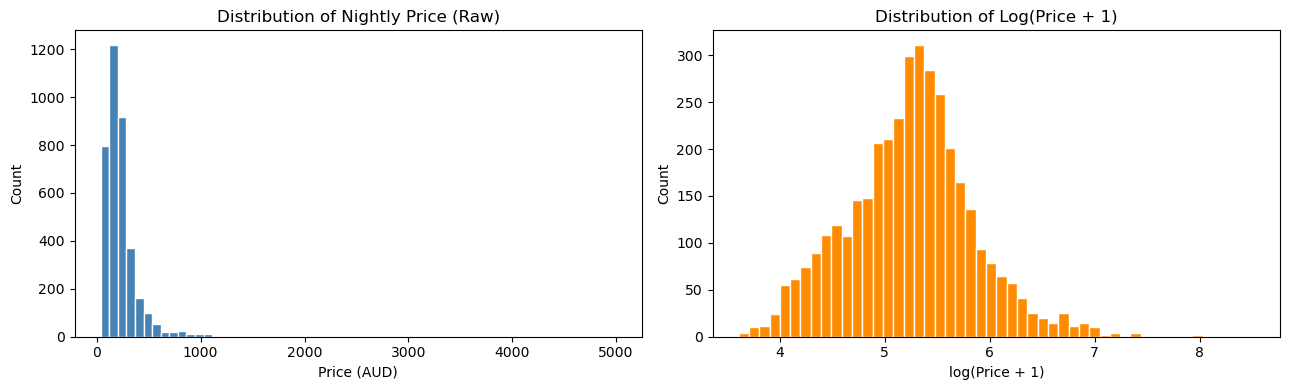

Price Stats:
count    3735.00
mean      230.08
std       194.65
min        36.00
25%       129.00
50%       193.00
75%       267.00
max      5000.00
Name: price, dtype: float64


In [34]:
# ── 1. Price Distribution ──
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(train['price'], bins=60, color='steelblue', edgecolor='white')
axes[0].set_title('Distribution of Nightly Price (Raw)')
axes[0].set_xlabel('Price (AUD)')
axes[0].set_ylabel('Count')

axes[1].hist(np.log1p(train['price']), bins=50, color='darkorange', edgecolor='white')
axes[1].set_title('Distribution of Log(Price + 1)')
axes[1].set_xlabel('log(Price + 1)')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.savefig('price_distribution.png', dpi=120, bbox_inches='tight')
plt.show()
print("Price Stats:")
print(train['price'].describe().round(2))

The raw price histogram shows that Airbnb listing prices are strongly right-skewed. Most listings are concentrated below the lower price range, while a small number of listings have very high prices, with the maximum price reaching **$5,000**. This indicates the presence of expensive or luxury listings that stretch the distribution.

The log-transformed price distribution appears more balanced and closer to a normal shape. This helps show the central pattern of prices more clearly because the extreme high prices have less visual influence after transformation.

#### 4.3 Distribution of property capacity variables

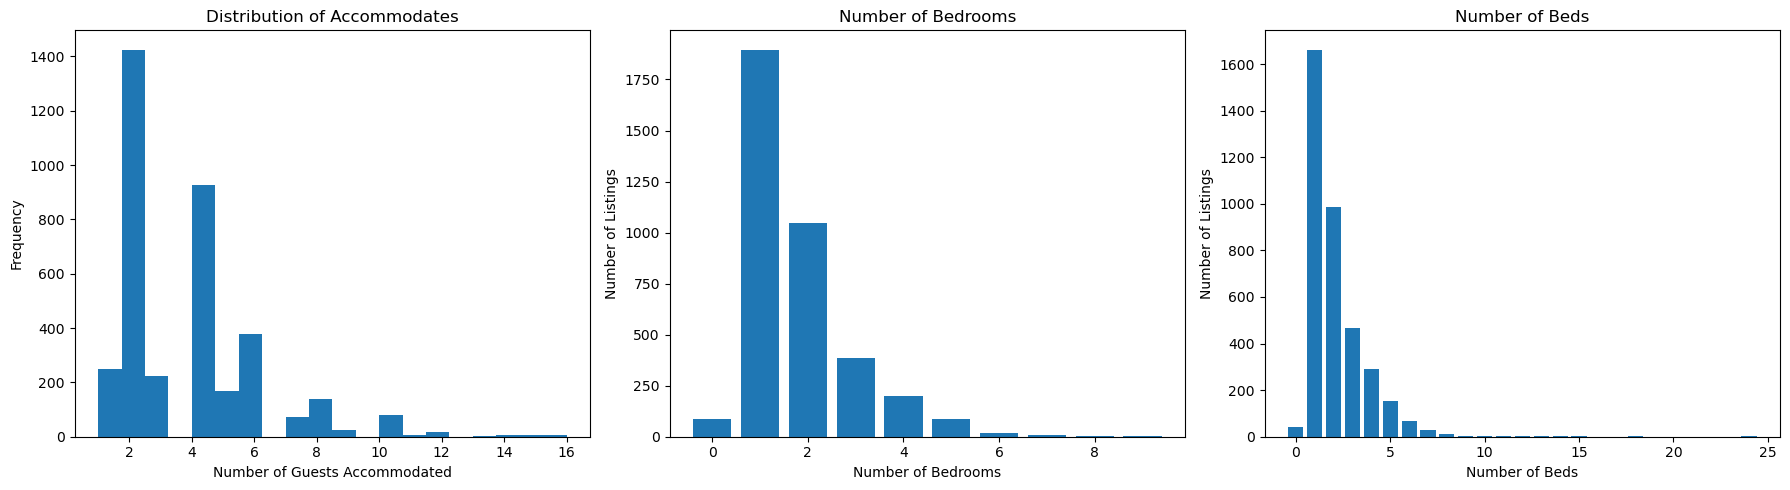

In [37]:
# Capacity-related variables shown side by side

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Histogram of accommodates
axes[0].hist(train["accommodates"].dropna(), bins=20)
axes[0].set_xlabel("Number of Guests Accommodated")
axes[0].set_ylabel("Frequency")
axes[0].set_title("Distribution of Accommodates")

# Bar chart of bedrooms
bedroom_counts = train["bedrooms"].value_counts().sort_index()
axes[1].bar(bedroom_counts.index, bedroom_counts.values)
axes[1].set_xlabel("Number of Bedrooms")
axes[1].set_ylabel("Number of Listings")
axes[1].set_title("Number of Bedrooms")

# Bar chart of beds
bed_counts = train["beds"].value_counts().sort_index()
axes[2].bar(bed_counts.index, bed_counts.values)
axes[2].set_xlabel("Number of Beds")
axes[2].set_ylabel("Number of Listings")
axes[2].set_title("Number of Beds")

plt.tight_layout()
plt.show()

The capacity-related charts show that most Brisbane Airbnb listings are designed for smaller groups. The `accommodates` chart shows that listings for **2 guests** and **4 guests** are especially common. This suggests that many properties are suitable for couples, solo travellers, or small families.

The bedroom chart shows that **1-bedroom** listings are the most common, followed by **2-bedroom** listings. Similarly, the beds chart shows that most listings have only a small number of beds, with **1 or 2 beds** being the most frequent. Larger listings with many bedrooms or beds exist, but they are much less common.

#### 4.4 Availability

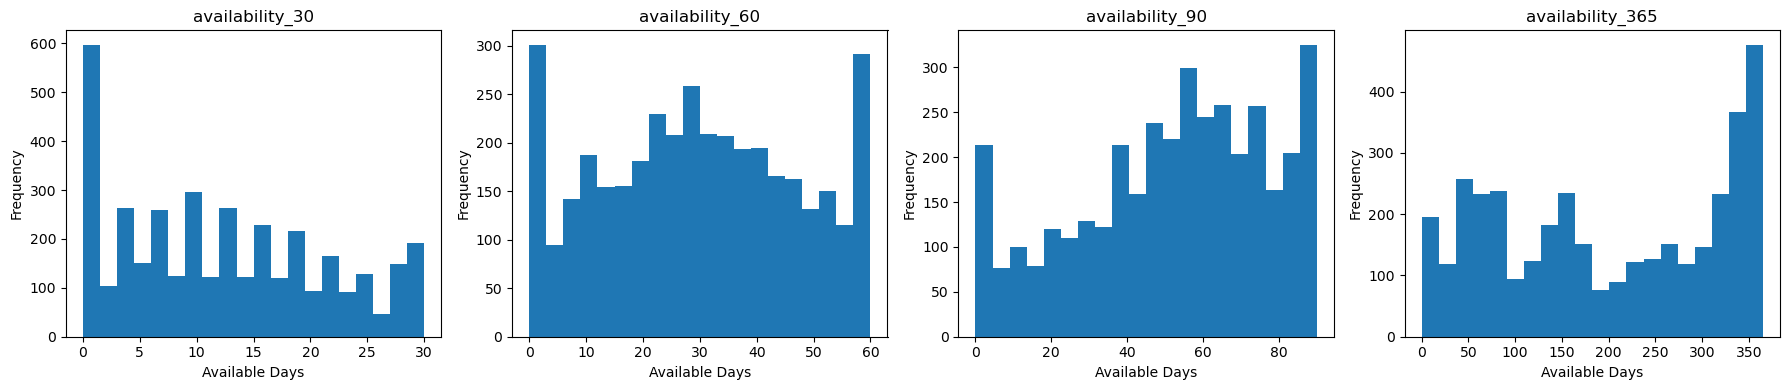

In [40]:
# Histograms of availability variables

availability_cols = [
    "availability_30",
    "availability_60",
    "availability_90",
    "availability_365"
]

fig, axes = plt.subplots(1, 4, figsize=(18, 4))

for i, col in enumerate(availability_cols):
    axes[i].hist(train[col].dropna(), bins=20)
    axes[i].set_title(col)
    axes[i].set_xlabel("Available Days")
    axes[i].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

The availability histograms show the distribution of listing availability over the next 30, 60, 90, and 365 days. Across all four variables, listings exhibit a wide range of availability levels, indicating differences in how frequently properties are available for booking.

For **availability_30**, **availability_60**, and **availability_90**, listings are spread across the full range of available days, suggesting variation in booking activity and host availability. Some listings have very few available days, while others remain available for most of the period.

The **availability_365** distribution shows a noticeable concentration of listings with high annual availability, particularly near the upper end of the scale. This suggests that many listings are available for a large portion of the year. At the same time, a substantial number of listings have lower annual availability, indicating considerable variation in listing activity across the dataset.

#### 4.5 Review-related variables

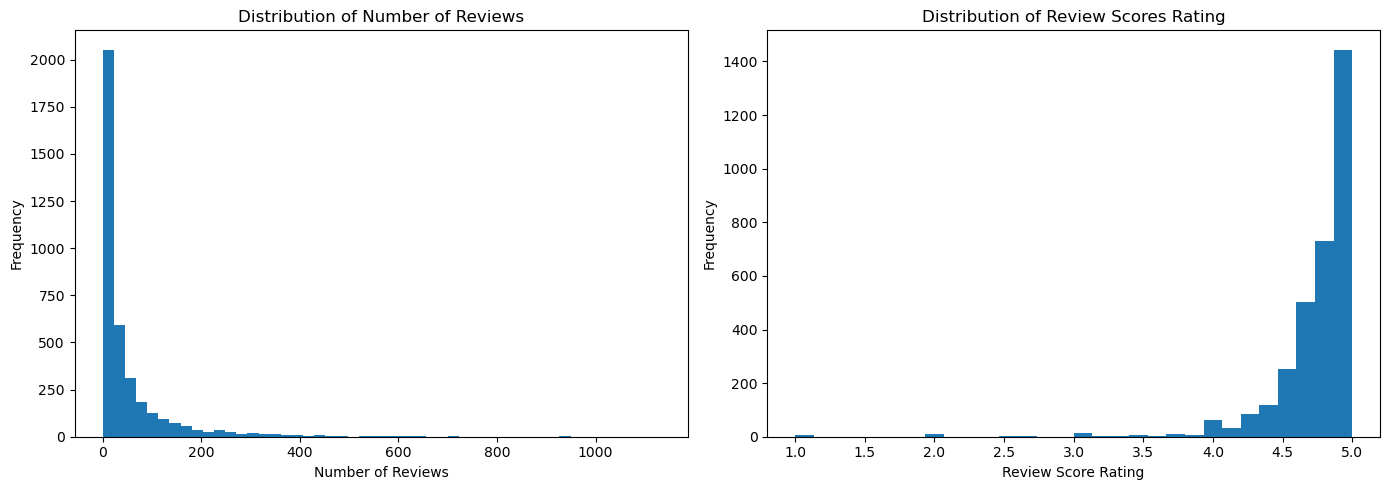

In [43]:
# Review-related variables shown side by side

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram of number_of_reviews
axes[0].hist(train["number_of_reviews"].dropna(), bins=50)
axes[0].set_xlabel("Number of Reviews")
axes[0].set_ylabel("Frequency")
axes[0].set_title("Distribution of Number of Reviews")

# Histogram of review_scores_rating
axes[1].hist(train["review_scores_rating"].dropna(), bins=30)
axes[1].set_xlabel("Review Score Rating")
axes[1].set_ylabel("Frequency")
axes[1].set_title("Distribution of Review Scores Rating")

plt.tight_layout()
plt.show()

The **number_of_reviews** histogram is strongly right-skewed. Most listings have a relatively small number of reviews, while only a small proportion of listings have received hundreds of reviews. This suggests that review activity is concentrated among a limited number of listings, whereas many listings have comparatively few reviews.

The **review_scores_rating** histogram shows that most reviewed listings have high ratings, with scores heavily concentrated between 4.5 and 5.0. This indicates generally positive guest experiences among reviewed listings. The variable also contains missing values, which may reflect listings that have not yet received enough guest reviews to generate a rating.

#### 4.6 Room type

In [46]:
# Count listings with review rating below 4.5

low_rating_count = train[train["review_scores_rating"] < 4.5].shape[0]

print("Number of listings with rating below 4.5:", low_rating_count)

Number of listings with rating below 4.5: 398


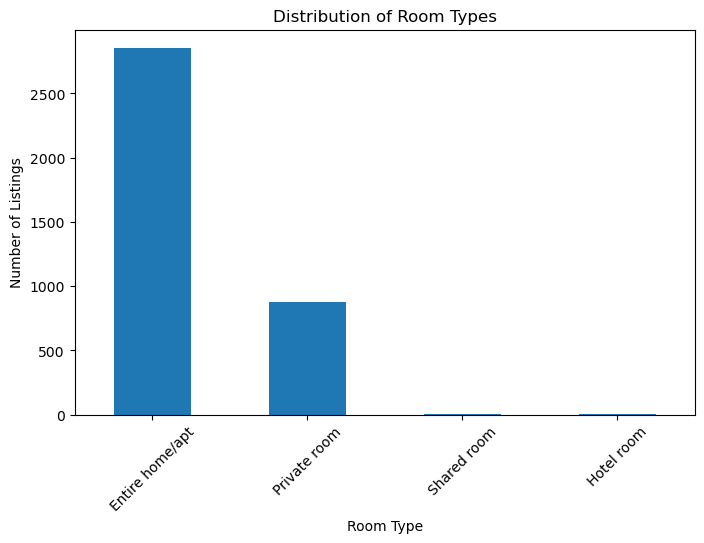

In [47]:
# Bar chart of room type

train["room_type"].value_counts().plot(kind="bar", figsize=(8, 5))
plt.xlabel("Room Type")
plt.ylabel("Number of Listings")
plt.title("Distribution of Room Types")
plt.xticks(rotation=45)
plt.show()

The room type chart shows that **Entire home/apartment** listings are the most common room type in the training dataset, accounting for the majority of listings. **Private rooms** are the second most common category, while **shared rooms** and **hotel rooms** represent only a very small proportion of listings.

This distribution indicates that the dataset is dominated by entire-property rentals rather than shared accommodation options. The room type variable may be an important predictor of Airbnb prices because different room types offer varying levels of privacy, space, and amenities.

#### 4.7 Property type

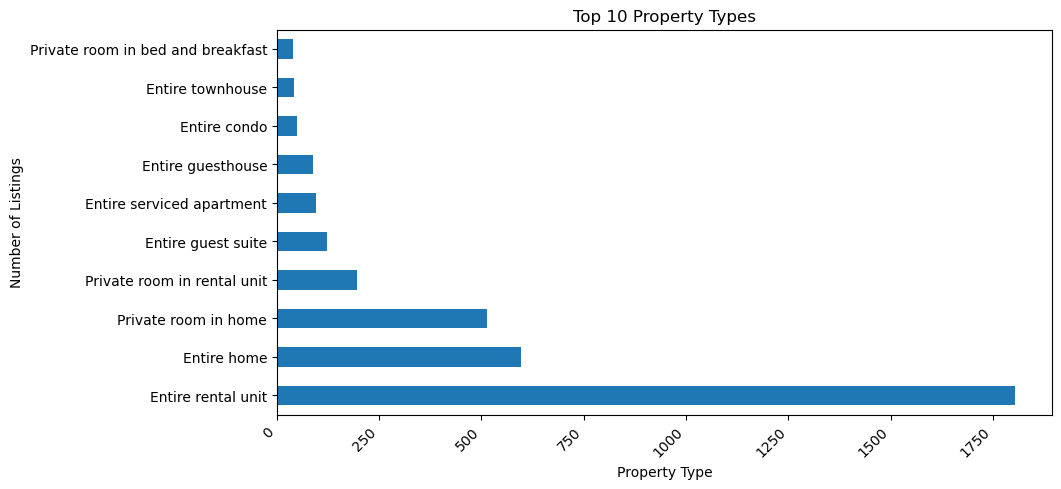

In [50]:
# Top 10 property types

train["property_type"].value_counts().head(10)
# Bar chart of top 10 property types

train["property_type"].value_counts().head(10).plot(kind="barh", figsize=(10, 5))
plt.xlabel("Property Type")
plt.ylabel("Number of Listings")
plt.title("Top 10 Property Types")
plt.xticks(rotation=45, ha="right")
plt.show()

The property type chart shows that **entire rental unit** is the most common property type by a large margin. Other common property types include **entire home**, **private room in home**, and **private room in rental unit**. The remaining property types occur much less frequently.

This distribution indicates that the dataset is concentrated in a small number of property categories, with entire-property rentals being particularly dominant. Since different property types offer varying levels of space, privacy, and amenities, **property type may be an important factor influencing Airbnb prices**.

#### 4.8 Neighbourhood/location

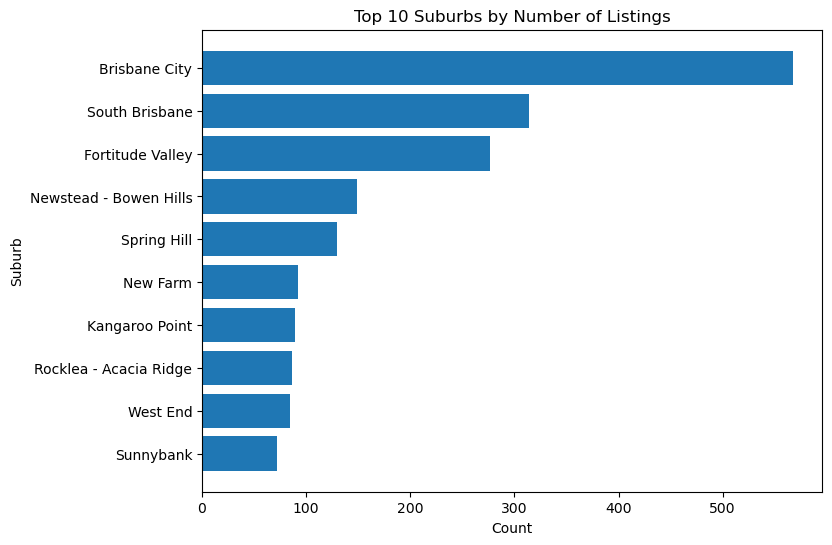

In [53]:
# Top 10 suburbs by number of listings

top_suburbs = train["neighbourhood_cleansed"].value_counts().head(10)

plt.figure(figsize=(8, 6))
plt.barh(top_suburbs.index, top_suburbs.values)
plt.xlabel("Count")
plt.ylabel("Suburb")
plt.title("Top 10 Suburbs by Number of Listings")
plt.gca().invert_yaxis()
plt.show()

The neighbourhood chart shows that Airbnb listings are concentrated in specific **Brisbane suburbs** rather than being evenly distributed across the city. **Brisbane City** has the highest number of listings, followed by **South Brisbane** and **Fortitude Valley**. These suburbs are located near the city centre and are popular destinations for tourists and business travellers, which may contribute to their higher listing counts.

Other suburbs, including Newstead–Bowen Hills, Spring Hill, New Farm, Kangaroo Point, and West End, also appear among the top 10 suburbs. Overall, the chart indicates that Airbnb listings are more concentrated in inner-city and high-demand areas, indicating stronger accommodation demand in these locations.

In [55]:
print("Duplicate rows in training dataset:", train.duplicated().sum())
print("Duplicate rows in test dataset:", test.duplicated().sum())

Duplicate rows in training dataset: 0
Duplicate rows in test dataset: 0


In [56]:
# Display examples of hosts with multiple listings in the training dataset

duplicate_hosts_train = train[train["host_id"].duplicated(keep=False)]

duplicate_hosts_train[
    ["host_id", "host_name", "neighbourhood_cleansed", "room_type", "property_type", "price"]
].sort_values("host_id").head(20)

,host_id,host_name,neighbourhood_cleansed,room_type,property_type,price
1292,161432,Ann,Wavell Heights,Entire home/apt,Entire guest suite,218.0
2543,161432,Ann,Wavell Heights,Entire home/apt,Entire guest suite,218.0
2337,369051,David & Nick,Paddington - Milton,Entire home/apt,Entire guest suite,265.0
1485,369051,David & Nick,Bardon,Entire home/apt,Entire guest suite,164.0
1400,1144833,Tanya,South Brisbane,Entire home/apt,Entire rental unit,534.0
1009,1144833,Tanya,Grange,Entire home/apt,Entire home,478.0
692,1144833,Tanya,Grange,Private room,Private room in home,111.0
365,1422218,Efrat,West End,Private room,Private room in home,120.0
1118,1422218,Efrat,West End,Private room,Private room in home,84.0
737,2318421,Bell,Auchenflower,Entire home/apt,Entire rental unit,335.0


In [57]:
review_cols = [
    "review_scores_rating",
    "review_scores_accuracy",
    "review_scores_cleanliness",
    "review_scores_checkin",
    "review_scores_communication",
    "review_scores_location",
    "review_scores_value"
]

# Correlation between overall rating and review sub-scores
train[review_cols].corr()["review_scores_rating"].sort_values(ascending=False)

review_scores_rating           1.000000
review_scores_value            0.886420
review_scores_accuracy         0.860718
review_scores_cleanliness      0.824455
review_scores_communication    0.769600
review_scores_location         0.688661
review_scores_checkin          0.644790
Name: review_scores_rating, dtype: float64

<hr style="width:25%;margin-left:0;">   

#### 5. Feature Analysis and Selection (2 marks)  
Select at least 20 meaningful features from the dataset.  

- Categorise each feature according to its variable type and present the results in a table (similar to Assignment 1)  
- Analyse how key features relate to the target variable (*price*) using appropriate plots and/or summary statistics  
- Justify your feature selection based on your analysis  
---



In [60]:
# Selected features and variable types

selected_features = pd.DataFrame({
    "Feature": [
        "host_since",
        "host_response_time",
        "host_response_rate",
        "host_acceptance_rate",
        "host_is_superhost",
        "host_listings_count",
        "neighbourhood_cleansed",
        "property_type",
        "room_type",
        "accommodates",
        "bathrooms",
        "bedrooms",
        "beds",
        "amenities",
        "minimum_nights",
        "maximum_nights",
        "availability_30",
        "availability_60",
        "availability_90",
        "availability_365",
        "number_of_reviews",
        "number_of_reviews_ltm",
        "number_of_reviews_l30d",
        "review_scores_rating",
        "review_scores_location",
        "review_scores_value",
        "instant_bookable",
        "reviews_per_month"
    ],
    "Variable Type": [
        "Date",
        "Ordinal",
        "Numeric percentage",
        "Numeric percentage",
        "Binary",
        "Numeric",
        "Nominal",
        "Nominal",
        "Nominal",
        "Numeric",
        "Numeric",
        "Numeric",
        "Numeric",
        "Text/List",
        "Numeric",
        "Numeric",
        "Numeric",
        "Numeric",
        "Numeric",
        "Numeric",
        "Numeric",
        "Numeric",
        "Numeric",
        "Numeric",
        "Numeric",
        "Numeric",
        "Binary",
        "Numeric"
    ],
    "Feature Group": [
        "Host profile",
        "Host communication",
        "Host communication",
        "Host behaviour",
        "Host reputation",
        "Host scale",
        "Location",
        "Property type",
        "Property type",
        "Property capacity",
        "Property size",
        "Property size",
        "Property capacity",
        "Property quality",
        "Booking rules",
        "Booking rules",
        "Availability",
        "Availability",
        "Availability",
        "Availability",
        "Reviews",
        "Reviews",
        "Reviews",
        "Guest reputation",
        "Guest reputation",
        "Guest reputation",
        "Booking flexibility",
        "Reviews"
    ],
    "Reason for Selection": [
        "May indicate host experience on Airbnb.",
        "Shows how quickly the host usually responds to guests.",
        "Measures host responsiveness as a percentage.",
        "Shows how often the host accepts booking requests.",
        "Indicates whether the host has Superhost status.",
        "Shows whether the host manages one or multiple listings.",
        "Captures suburb-level location differences.",
        "Describes the specific type of property.",
        "Shows whether the listing is an entire home, private room, shared room, or hotel room.",
        "Measures how many guests the listing can host.",
        "Indicates the number of bathrooms available.",
        "Shows the number of bedrooms in the listing.",
        "Shows the sleeping capacity of the listing.",
        "Captures facilities and features offered by the listing.",
        "Shows the minimum number of nights required for a booking.",
        "Shows the maximum number of nights allowed for a booking.",
        "Measures short-term listing availability over 30 days.",
        "Measures listing availability over 60 days.",
        "Measures listing availability over 90 days.",
        "Measures yearly listing availability.",
        "Shows total guest review activity.",
        "Shows review activity over the last 12 months.",
        "Shows recent review activity over the last 30 days.",
        "Measures overall guest satisfaction.",
        "Captures guest rating of the listing location.",
        "Shows whether guests felt the listing provided good value.",
        "Shows whether guests can book immediately without host approval.",
        "Measures review frequency per month."
    ]
})

selected_features

,Feature,Variable Type,Feature Group,Reason for Selection
0,host_since,Date,Host profile,May indicate host experience on Airbnb.
1,host_response_time,Ordinal,Host communication,Shows how quickly the host usually responds to...
2,host_response_rate,Numeric percentage,Host communication,Measures host responsiveness as a percentage.
3,host_acceptance_rate,Numeric percentage,Host behaviour,Shows how often the host accepts booking reque...
4,host_is_superhost,Binary,Host reputation,Indicates whether the host has Superhost status.
5,host_listings_count,Numeric,Host scale,Shows whether the host manages one or multiple...
6,neighbourhood_cleansed,Nominal,Location,Captures suburb-level location differences.
7,property_type,Nominal,Property type,Describes the specific type of property.
8,room_type,Nominal,Property type,"Shows whether the listing is an entire home, p..."
9,accommodates,Numeric,Property capacity,Measures how many guests the listing can host.


In [61]:
import pandas as pd

# Feature classification

numeric_features = [
    "host_response_rate",
    "host_acceptance_rate",
    "host_listings_count",
    "accommodates",
    "bathrooms",
    "bedrooms",
    "beds",
    "minimum_nights",
    "maximum_nights",
    "availability_30",
    "availability_60",
    "availability_90",
    "availability_365",
    "number_of_reviews",
    "number_of_reviews_ltm",
    "number_of_reviews_l30d",
    "review_scores_rating",
    "review_scores_location",
    "review_scores_value",
    "reviews_per_month"
]

ordinal_features = [
    "host_response_time"
]

nominal_features = [
    "host_is_superhost",
    "neighbourhood_cleansed",
    "property_type",
    "room_type",
    "amenities",
    "instant_bookable"
]

# Create summary table
feature_summary = pd.DataFrame({
    "Variable Type": ["Numeric", "Ordinal", "Nominal"],
    "Number of Features": [
        len(numeric_features),
        len(ordinal_features),
        len(nominal_features)
    ],
    "Feature Names": [
        ", ".join(numeric_features),
        ", ".join(ordinal_features),
        ", ".join(nominal_features)
    ]
})

# Display table
feature_summary

,Variable Type,Number of Features,Feature Names
0,Numeric,20,"host_response_rate, host_acceptance_rate, host..."
1,Ordinal,1,host_response_time
2,Nominal,6,"host_is_superhost, neighbourhood_cleansed, pro..."


**Variable type explanation**


The table groups the selected features into three variable types based on their characteristics and how they are used in the analysis.

**Numeric variables** -  (**host_response_rate, host_acceptance_rate, host_listings_count, accommodates, bathrooms, bedrooms, beds, minimum_nights, maximum_nights, availability_30, availability_60, availability_90, availability_365, number_of_reviews, number_of_reviews_ltm, number_of_reviews_l30d, review_scores_rating, review_scores_location, review_scores_value, and reviews_per_month**) represent measurable values that can be used directly in calculations, statistical analysis, and predictive modelling.

**Ordinal variables** - (**host_response_time**) consist of ordered categories where the ranking is meaningful, such as the time taken by hosts to respond to guest inquiries.

**Nominal variables** - (**host_is_superhost, neighbourhood_cleansed, property_type, room_type, amenities, and instant_bookable**) are categorical variables with no inherent order and are used to classify listings into different groups.

The variable **host_since** was excluded from this classification because it is a temporal (date) variable rather than a numeric or categorical feature.

 ### Relationship Between Key Features and Price

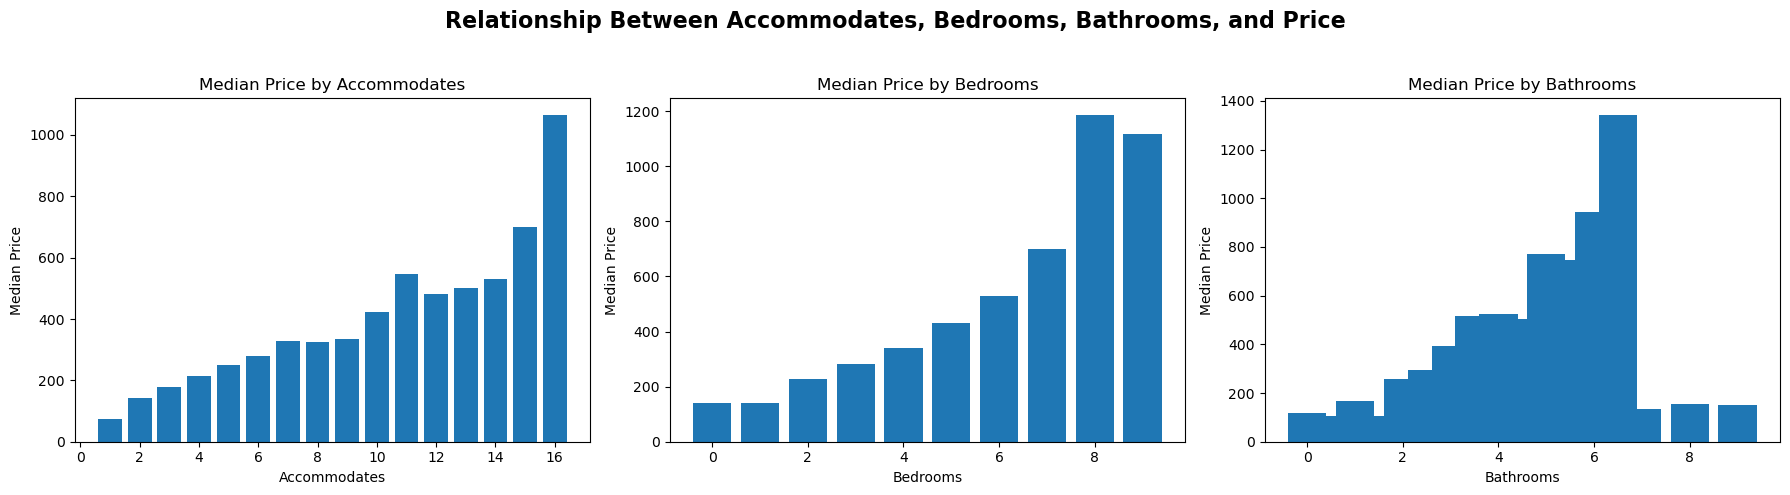

In [64]:
# Median price by accommodates, bedrooms, and bathrooms

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

accom_price = train.groupby("accommodates")["price"].median()
axes[0].bar(accom_price.index, accom_price.values)
axes[0].set_xlabel("Accommodates")
axes[0].set_ylabel("Median Price")
axes[0].set_title("Median Price by Accommodates")

bedroom_price = train.groupby("bedrooms")["price"].median()
axes[1].bar(bedroom_price.index, bedroom_price.values)
axes[1].set_xlabel("Bedrooms")
axes[1].set_ylabel("Median Price")
axes[1].set_title("Median Price by Bedrooms")

bathroom_price = train.groupby("bathrooms")["price"].median()
axes[2].bar(bathroom_price.index, bathroom_price.values)
axes[2].set_xlabel("Bathrooms")
axes[2].set_ylabel("Median Price")
axes[2].set_title("Median Price by Bathrooms")

# Overall figure title
fig.suptitle(
    "Relationship Between Accommodates, Bedrooms, Bathrooms, and Price",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

In [65]:
# ==========================================================
# Correlation Analysis of Selected Features and Price
# ==========================================================

# Create a copy for correlation analysis
corr_data = train.copy()

# Convert percentage columns to numeric if stored as text
percentage_cols = ["host_response_rate", "host_acceptance_rate"]

for col in percentage_cols:
    if corr_data[col].dtype == "object":
        corr_data[col] = (
            corr_data[col]
            .str.replace("%", "", regex=False)
            .astype(float)
        )

# Convert binary columns to numeric
binary_cols = ["host_is_superhost", "instant_bookable"]

for col in binary_cols:
    corr_data[col] = corr_data[col].map({
        "t": 1,
        "f": 0
    })

# Selected features
corr_features = [
    "price",
    "host_response_rate",
    "host_acceptance_rate",
    "host_is_superhost",
    "host_listings_count",
    "accommodates",
    "bathrooms",
    "bedrooms",
    "beds",
    "minimum_nights",
    "maximum_nights",
    "availability_30",
    "availability_60",
    "availability_90",
    "availability_365",
    "number_of_reviews",
    "number_of_reviews_ltm",
    "number_of_reviews_l30d",
    "review_scores_rating",
    "review_scores_location",
    "review_scores_value",
    "instant_bookable",
    "reviews_per_month"
]

# Create correlation matrix
corr_matrix = corr_data[corr_features].corr()

# ==========================================================
# Correlation Analysis with Price
# ==========================================================

print("=" * 70)
print("Correlation Analysis of Features and Price".center(70))
print("=" * 70)

sorted_corr_series = (
    corr_matrix["price"]
    .drop("price")
    .sort_values(ascending=False)
)

# Interpret and print
for feature, corr_val in sorted_corr_series.items():

    if corr_val > 0.5:
        strength = "Strong Positive Relationship"
    elif corr_val > 0.2:
        strength = "Moderate Positive Relationship"
    elif corr_val > 0:
        strength = "Weak Positive Relationship"
    else:
        strength = "Negative/Inversely Proportional Relationship"

    print(
        f"Feature: {feature:<25} | "
        f"Correlation: {corr_val:>7.4f} -> {strength}"
    )

print("=" * 70)

              Correlation Analysis of Features and Price              
Feature: accommodates              | Correlation:  0.5226 -> Strong Positive Relationship
Feature: bedrooms                  | Correlation:  0.5031 -> Strong Positive Relationship
Feature: beds                      | Correlation:  0.4877 -> Moderate Positive Relationship
Feature: bathrooms                 | Correlation:  0.4175 -> Moderate Positive Relationship
Feature: availability_30           | Correlation:  0.1165 -> Weak Positive Relationship
Feature: maximum_nights            | Correlation:  0.1044 -> Weak Positive Relationship
Feature: host_listings_count       | Correlation:  0.0819 -> Weak Positive Relationship
Feature: availability_60           | Correlation:  0.0784 -> Weak Positive Relationship
Feature: review_scores_location    | Correlation:  0.0742 -> Weak Positive Relationship
Feature: availability_90           | Correlation:  0.0610 -> Weak Positive Relationship
Feature: review_scores_rating      | 

### Correlation Strength Interpretation 

| Absolute Correlation Coefficient (r) | Interpretation |
|--------------------------------------|----------------|
| 0.00 – 0.19 | Very Weak Relationship |
| 0.20 – 0.39 | Weak Relationship |
| 0.40 – 0.59 | Moderate Relationship |
| 0.60 – 0.79 | Strong Relationship |
| 0.80 – 1.00 | Very Strong Relationship |

**Note:** The absolute value of the Pearson correlation coefficient was used to determine the strength of the relationship, while the sign indicates whether the relationship is positive or negative.

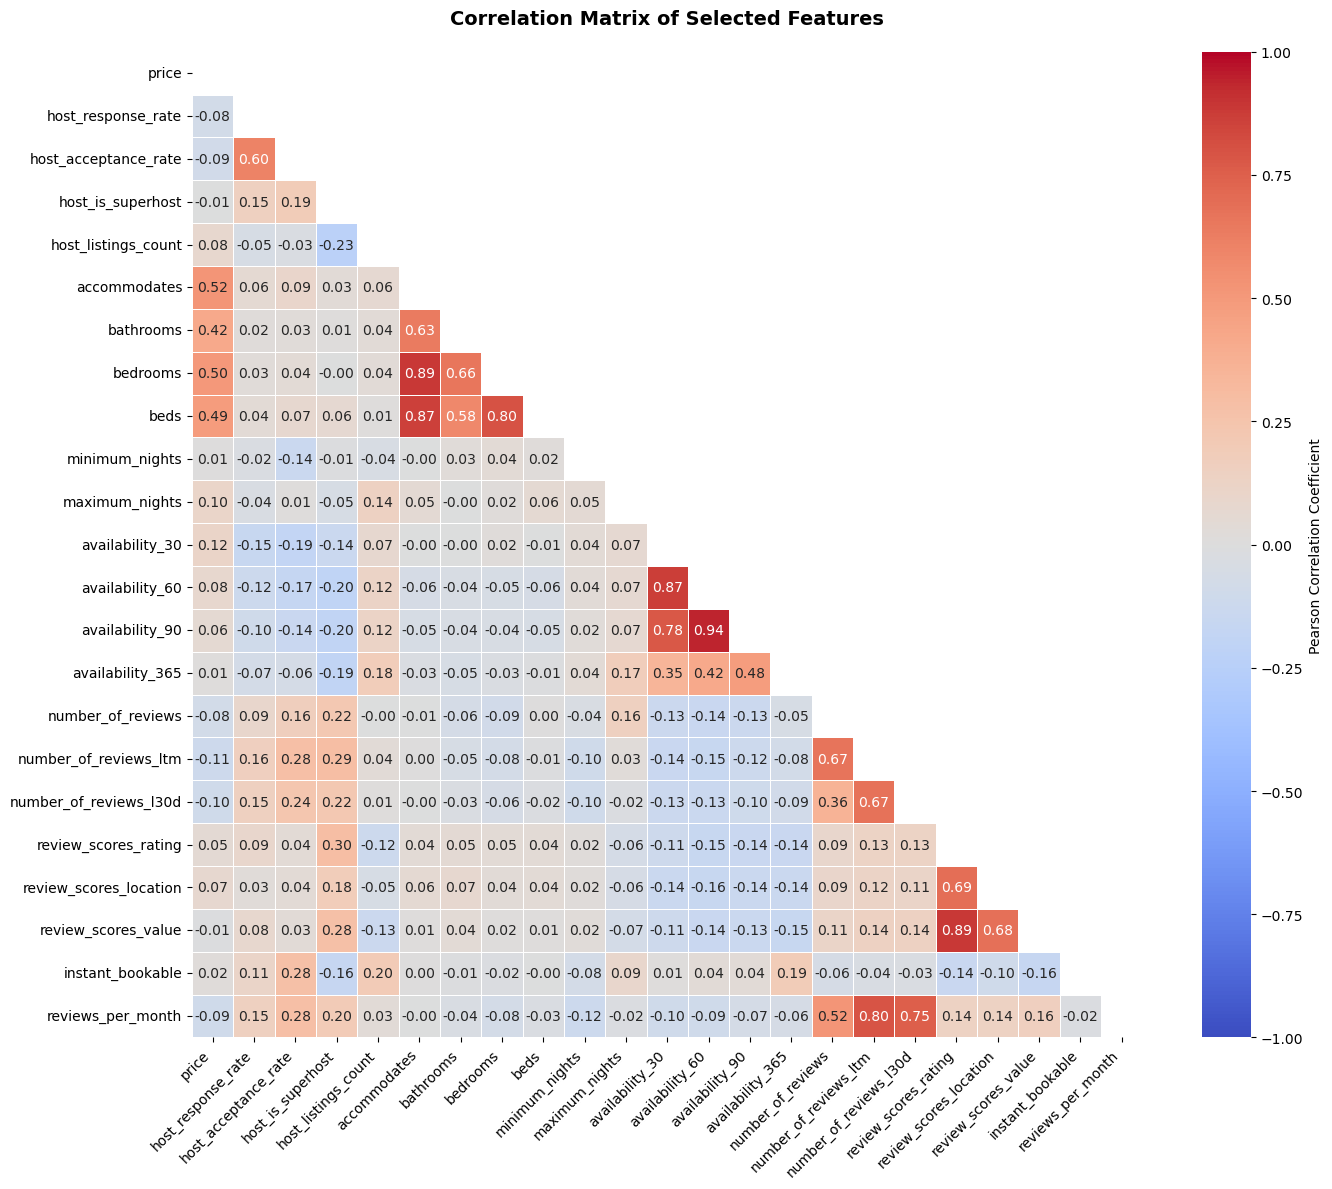

In [67]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Create upper triangle mask
mask = np.triu(
    np.ones_like(corr_matrix, dtype=bool)
)

# Plot heatmap
plt.figure(figsize=(14, 12))

sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    cbar_kws={
        "label": "Pearson Correlation Coefficient"
    }
)

plt.title(
    "Correlation Matrix of Selected Features",
    fontsize=14,
    fontweight="bold",
    pad=20
)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

#### Correlation Matrix of Selected Numeric Features

The correlation analysis reveals that property size and accommodation capacity have the strongest relationships with price. Among all selected features, accommodates (r = 0.523) and bedrooms (r = 0.503) exhibit strong positive correlations with price, indicating that listings capable of hosting more guests and offering more bedrooms tend to command higher prices. Similarly, beds (r = 0.488) and bathrooms (r = 0.418) show moderate positive correlations, further suggesting that larger and better-equipped properties are generally associated with higher listing prices.

Most remaining variables exhibit weak relationships with price. Features such as availability_30, maximum_nights, host_listings_count, and review_scores_location display weak positive correlations, indicating a limited association with listing price. Conversely, number_of_reviews, host_response_rate, host_acceptance_rate, reviews_per_month, and recent review counts show weak negative correlations, suggesting that these factors have little direct influence on pricing.

The correlation results show that the strongest positive relationships with `price` are mainly property capacity and size variables. `accommodates` has the strongest positive correlation with price at approximately **0.52**, followed by `bedrooms` at approximately **0.50**, `beds` at approximately **0.49**, and `bathrooms` at approximately **0.42**. This suggests that larger Airbnb listings generally tend to have higher prices, which is expected because they can host more guests and usually provide more space and facilities.

Most host-related variables show weak relationships with price. For example, `host_response_rate` and `host_acceptance_rate` have small negative correlations with price, while `host_is_superhost` has almost no direct correlation with price. This suggests that host communication and reliability may still be useful supporting features, but they are unlikely to be the main drivers of listing price.

Review-related variables also show relatively weak correlations with price. `review_scores_location` and `review_scores_rating` have small positive correlations, while `review_scores_value` is close to zero.  Review variables may still be useful because they reflect guest satisfaction and listing reputation, but their relationship with price appears weaker than property size variables.

The correlation matrix also shows strong relationships between some features themselves. For example, `accommodates`, `bedrooms`, and `beds` are highly correlated with each other because they all describe property capacity. Similarly, availability variables are related to each other because they measure listing availability over different time periods.

#### Analysis of Selected Non-Numeric Features

Some selected features are categorical, date-based, or text-based, so they were not included directly in the numeric correlation matrix. Instead, these variables were analysed using grouped median prices or simple derived features. This is more appropriate because variables such as `room_type`, `property_type`, and `neighbourhood_cleansed` represent categories rather than continuous numeric values.

In [71]:
# Prepare grouped median price summaries for selected non-numeric features

# 1. Median price by room type
room_price = train.groupby("room_type")["price"].median().sort_values(ascending=False)


# 2. Median price by common property types
# Only include property types with at least 20 listings to avoid unreliable small groups

property_counts = train["property_type"].value_counts()
common_property_types = property_counts[property_counts >= 20].index

property_price = (
    train[train["property_type"].isin(common_property_types)]
    .groupby("property_type")["price"]
    .median()
    .sort_values(ascending=False)
    .head(10)
)


# 3. Median price by common suburbs
# Only include suburbs with at least 20 listings to avoid unreliable small groups

suburb_counts = train["neighbourhood_cleansed"].value_counts()
common_suburbs = suburb_counts[suburb_counts >= 20].index

suburb_price = (
    train[train["neighbourhood_cleansed"].isin(common_suburbs)]
    .groupby("neighbourhood_cleansed")["price"]
    .median()
    .sort_values(ascending=False)
    .head(10)
)


# 4. Median price by host response time
response_price = train.groupby("host_response_time")["price"].median().sort_values(ascending=False)


# 5. Create amenities count and amenities group
# The amenities column is text/list-like, so we count the number of listed amenities


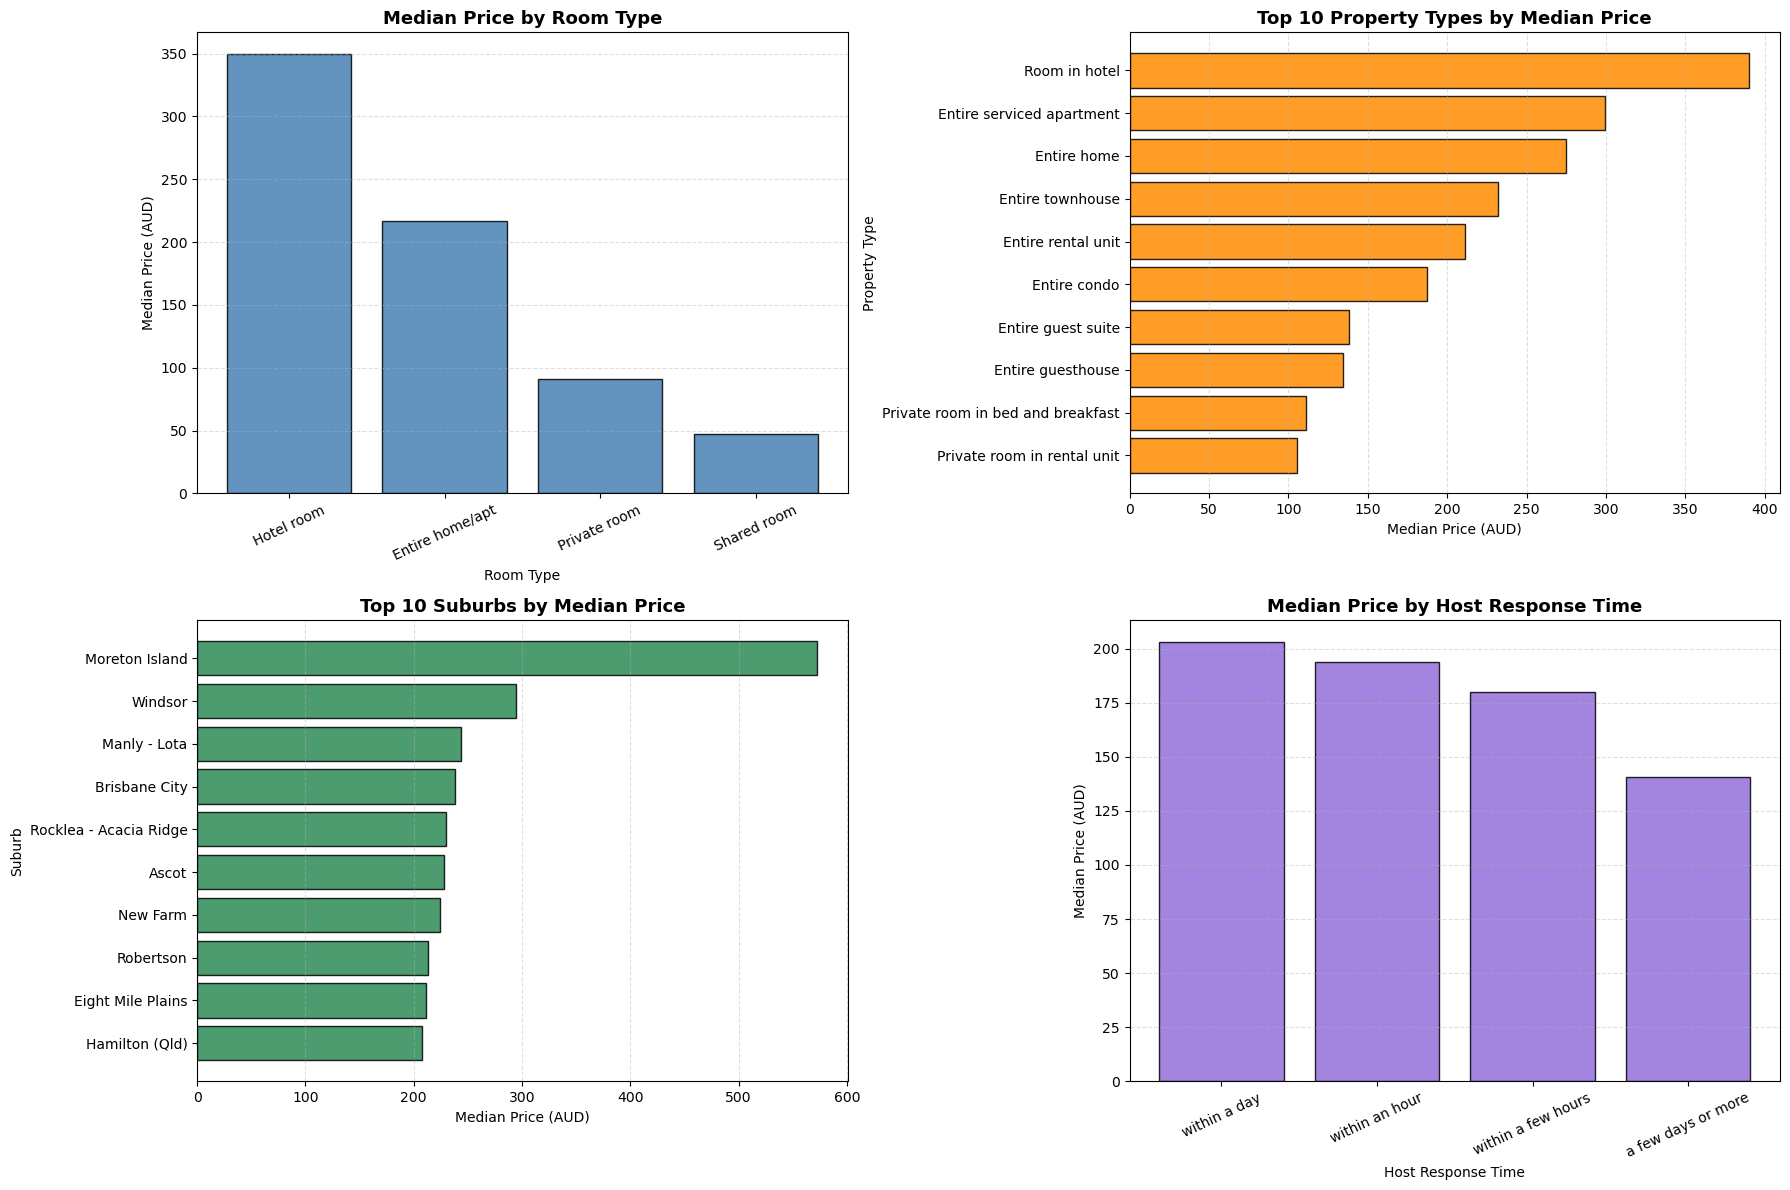

In [72]:
# Plot selected non-numeric feature relationships with price

fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# Colours for each chart
colors = {
    "room": "steelblue",
    "property": "darkorange",
    "suburb": "seagreen",
    "response": "mediumpurple"
}

# Room type
axes[0, 0].bar(
    room_price.index,
    room_price.values,
    color=colors["room"],
    edgecolor="black",
    alpha=0.85
)
axes[0, 0].set_title(
    "Median Price by Room Type",
    fontsize=13,
    fontweight="bold"
)
axes[0, 0].set_xlabel("Room Type")
axes[0, 0].set_ylabel("Median Price (AUD)")
axes[0, 0].tick_params(axis="x", rotation=25)
axes[0, 0].grid(axis="y", linestyle="--", alpha=0.4)

# Property type
axes[0, 1].barh(
    property_price.index,
    property_price.values,
    color=colors["property"],
    edgecolor="black",
    alpha=0.85
)
axes[0, 1].set_title(
    "Top 10 Property Types by Median Price",
    fontsize=13,
    fontweight="bold"
)
axes[0, 1].set_xlabel("Median Price (AUD)")
axes[0, 1].set_ylabel("Property Type")
axes[0, 1].invert_yaxis()
axes[0, 1].grid(axis="x", linestyle="--", alpha=0.4)

# Neighbourhood
axes[1, 0].barh(
    suburb_price.index,
    suburb_price.values,
    color=colors["suburb"],
    edgecolor="black",
    alpha=0.85
)
axes[1, 0].set_title(
    "Top 10 Suburbs by Median Price",
    fontsize=13,
    fontweight="bold"
)
axes[1, 0].set_xlabel("Median Price (AUD)")
axes[1, 0].set_ylabel("Suburb")
axes[1, 0].invert_yaxis()
axes[1, 0].grid(axis="x", linestyle="--", alpha=0.4)

# Host response time
axes[1, 1].bar(
    response_price.index,
    response_price.values,
    color=colors["response"],
    edgecolor="black",
    alpha=0.85
)
axes[1, 1].set_title(
    "Median Price by Host Response Time",
    fontsize=13,
    fontweight="bold"
)
axes[1, 1].set_xlabel("Host Response Time")
axes[1, 1].set_ylabel("Median Price (AUD)")
axes[1, 1].tick_params(axis="x", rotation=25)
axes[1, 1].grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

#### Non-Numeric and Derived Feature Analysis

The selected categorical and text-based features were analysed using median price comparisons. Median price was used instead of mean price because Airbnb prices are right-skewed and contain high-price outliers. 

The `room_type` comparison shows clear price differences across accommodation types. Hotel rooms and entire homes/apartments have higher median prices than private rooms and shared rooms. This supports the selection of `room_type` because it captures the level of privacy and space offered to guests.

The `property_type` comparison also shows differences in median price. Property types such as rooms in hotels, entire serviced apartments, and entire homes have higher median prices than private-room categories. This suggests that the specific form of accommodation is relevant to listing price.

The suburb comparison shows that median prices vary across Brisbane neighbourhoods. Moreton Island, Windsor, Manly - Lota, and Brisbane City appear among the higher-priced common suburbs. This supports the selection of `neighbourhood_cleansed` because location is an important part of accommodation pricing.

The host response time chart shows only a moderate difference in median price across response categories. This suggests that host communication may provide some useful context, but it is not likely to be a major direct price driver compared with property size, room type, and location.

The amenities analysis shows that listings with more amenities generally have higher median prices, especially listings with more than 40 amenities. This supports the idea that amenities can increase the perceived value of a listing.

#### Justification for Feature Selection

The selected features were chosen because they represent the main factors that may explain Airbnb listing prices. Property size and capacity variables such as `accommodates`, `bathrooms`, `bedrooms`, and `beds` were selected because the correlation analysis showed that these variables have the strongest positive relationships with price. Larger listings can host more guests and usually provide more space, which supports higher prices.

Location and listing-type variables were also selected because the median price comparisons showed clear differences across `neighbourhood_cleansed`, `room_type`, and `property_type`. This suggests that where a listing is located and the type of accommodation offered are important price-related factors.

Review-related variables such as `number_of_reviews`, `reviews_per_month`, `review_scores_rating`, `review_scores_location`, and `review_scores_value` were selected because they describe guest activity, satisfaction, and perceived listing quality. Although their direct correlation with price is weaker, they still provide useful information about listing reputation.

Host-related variables such as `host_response_time`, `host_response_rate`, `host_acceptance_rate`, `host_is_superhost`, and `host_listings_count` were selected because they describe host reliability, responsiveness, and experience managing listings. These features may not be the strongest direct price drivers, but they provide useful supporting information.

Availability and booking-rule variables such as `availability_30`, `availability_60`, `availability_90`, `availability_365`, `minimum_nights`, and `maximum_nights` were selected because they describe how the listing is managed and how flexible it is for guests. The `amenities` variable was also selected because the derived amenities count showed that listings with more amenities generally had higher median prices.

Overall, the analysis supports the selected feature set because it covers property characteristics, location, listing type, host behaviour, booking rules, availability, reviews, and amenities. These categories provide a broad and meaningful basis for later data cleaning and feature engineering.

In [75]:
# Clean estimated_revenue_l365d if needed and check correlation with price

# Clean estimated_revenue_l365d
train["estimated_revenue_l365d"] = (
    train["estimated_revenue_l365d"]
    .replace(r'[$,]', '', regex=True)
    .astype(float)
)

# Show correlation matrix
display(train[["price", "estimated_revenue_l365d"]].corr())

,price,estimated_revenue_l365d
price,1.000000,0.263675
estimated_revenue_l365d,0.263675,1.000000


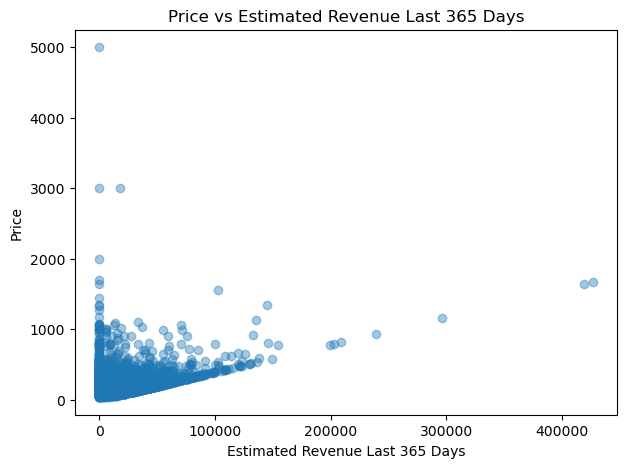

In [76]:
plt.figure(figsize=(7, 5))
plt.scatter(train["estimated_revenue_l365d"], train["price"], alpha=0.4)
plt.xlabel("Estimated Revenue Last 365 Days")
plt.ylabel("Price")
plt.title("Price vs Estimated Revenue Last 365 Days")
plt.show()

---
---

## Task 2: Data Cleaning, Missing Observations and Feature Engineering

**Total Marks: 10**

- Use the features selected in **Task 1, Question 5** for this task.  
- Ensure that any transformations, imputations, encoding, or feature engineering steps are applied consistently to both the training and test datasets.  
- Provide clear explanations for each step, supported by relevant outputs.

Student in charge of this task: `(insert name here)`

<hr style="width:25%;margin-left:0;">   

#### 1. Numerical Data Cleaning (2 marks)

Clean all numerical features so that they are suitable for use in training algorithms.
- Extract numerical values from text-based fields where necessary
- Remove non-numeric characters %, $, commas, etc.
- Briefly describe the steps you take

In [80]:
# Create cleaned copies of train and test datasets

train_clean = train.copy()
test_clean = test.copy()

# Clean target variable: price
# Remove "$" and "," before converting to numeric

train_clean["price"] = (
    train_clean["price"]
    .replace(r'[$,]', '', regex=True)
    .astype(float)
)

# Clean percentage columns
percentage_cols = ["host_response_rate", "host_acceptance_rate"]

for col in percentage_cols:

    train_clean[col] = (
        train_clean[col]
        .astype(str)
        .str.replace("%", "", regex=False)
        .replace("nan", np.nan)
        .astype(float)
    )

    test_clean[col] = (
        test_clean[col]
        .astype(str)
        .str.replace("%", "", regex=False)
        .replace("nan", np.nan)
        .astype(float)
    )

In [81]:
# Convert selected numerical columns to numeric format

numeric_cols = [
    "host_listings_count",
    "accommodates",
    "bathrooms",
    "bedrooms",
    "beds",
    "minimum_nights",
    "maximum_nights",
    "availability_30",
    "availability_60",
    "availability_90",
    "availability_365",
    "number_of_reviews",
    "number_of_reviews_ltm",
    "number_of_reviews_l30d",
    "review_scores_rating",
    "review_scores_location",
    "review_scores_value",
    "reviews_per_month"
]

for col in numeric_cols:
    train_clean[col] = pd.to_numeric(train_clean[col], errors="coerce")
    test_clean[col] = pd.to_numeric(test_clean[col], errors="coerce")

In [82]:
# Convert binary true/false variables to numeric 1/0

binary_cols = ["host_is_superhost", "instant_bookable"]

for col in binary_cols:
    train_clean[col] = train_clean[col].map({"t": 1, "f": 0})
    test_clean[col] = test_clean[col].map({"t": 1, "f": 0})

In [83]:
# Check the first few cleaned values

train_clean[
    ["price", "host_response_rate", "host_acceptance_rate", 
     "host_is_superhost", "instant_bookable"]
].head()

,price,host_response_rate,host_acceptance_rate,host_is_superhost,instant_bookable
0,97.0,100.0,89.0,1.0,0
1,205.0,100.0,93.0,1.0,0
2,186.0,100.0,100.0,0.0,1
3,157.0,100.0,100.0,0.0,0
4,300.0,100.0,97.0,1.0,0


The first step was to clean numerical variables so they were suitable for later modelling. The target variable `price` was originally stored as text because it contained non-numeric characters such as `$` and commas. These symbols were removed and the column was converted into numeric `float` format.

The percentage variables `host_response_rate` and `host_acceptance_rate` were also cleaned because they were stored as text values containing `%` signs. The percentage signs were removed and the variables were converted into numeric form. 

The remaining selected numerical variables, including property size, availability, review count, and review score variables, were converted using `pd.to_numeric()`. This ensures that any unexpected non-numeric values are treated as missing values instead of causing errors later.

The binary variables `host_is_superhost` and `instant_bookable` were also converted into numeric form, where `t` was coded as 1 and `f` was coded as 0. This makes the binary variables suitable for later modelling while preserving their meaning.

Cleaned copies of the original datasets were created as `train_clean` and `test_clean` so that the original datasets remain unchanged. This makes the cleaning process safer and easier to review.

<hr style="width:25%;margin-left:0;">    

#### 2. Feature Engineering (2 marks)

Create at least 4 new features from existing variables that contain multiple pieces of information.  
- Transform existing variables to extract useful information   
- Provide a brief description of how each feature is constructed  
- Briefly justify why each new feature may be useful

#### 2. Feature Engineering

Four feature engineering steps were used to extract more useful information from existing variables. These features were created consistently for both the training and test datasets.

The engineered features were:
1. `parking_type`, created from the amenities text.
2. `revenue_per_occupied_day`, created from estimated revenue and occupancy.
3. `distance_to_city_centre_km`, created from latitude and longitude.
4. `Amenity value counts`, created by grouping amenities into low-, medium-, and high-price amenity groups.

#### 2.1 parking type

In [88]:
def get_parking_type(amenities):
    amenities = str(amenities).lower()
    
    if "no parking" in amenities:
        return "No parking"
    elif "free street parking" in amenities:
        return "Free street parking"
    elif "free parking" in amenities:
        return "Free parking"
    elif "paid street parking" in amenities:
        return "Paid street parking"
    elif "paid parking" in amenities:
        return "Paid parking"
    elif "street parking" in amenities:
        return "Street parking"
    elif "parking" in amenities:
        return "Parking available"
    else:
        return "Not stated"

train_clean["parking_type"] = train_clean["amenities"].apply(get_parking_type)
test_clean["parking_type"] = test_clean["amenities"].apply(get_parking_type)

In [89]:
# Check parking type distribution in training and test data

print("Training data:")
print(train_clean["parking_type"].value_counts())

print("\nTest data:")
print(test_clean["parking_type"].value_counts())

Training data:
parking_type
Free parking           1559
Free street parking    1178
Not stated              621
Paid parking            318
Paid street parking      31
Parking available        28
Name: count, dtype: int64

Test data:
parking_type
Free parking           662
Free street parking    502
Not stated             279
Paid parking           129
Parking available       16
Paid street parking     13
Name: count, dtype: int64


In [90]:
# Display sample rows for each parking type

pd.set_option("display.max_colwidth", None)

train_clean[["ID", "amenities", "parking_type"]].groupby("parking_type").head(1)

,ID,amenities,parking_type
0,0,"[""Hair dryer"", ""Hangers"", ""Fire extinguisher"", ""Essentials"", ""Shampoo"", ""Air conditioning"", ""Free parking on premises"", ""Iron"", ""Kitchen"", ""Heating"", ""Private entrance"", ""Smoke alarm"", ""TV"", ""Hot water"", ""Exterior security cameras on property"", ""Wifi"", ""Washer""]",Free parking
1,1,"[""Laundromat nearby"", ""Refrigerator"", ""Bed linens"", ""Extra pillows and blankets"", ""Lockbox"", ""Shared backyard \u2013 Fully fenced"", ""Smoke alarm"", ""Toaster"", ""Wifi"", ""Dishes and silverware"", ""Hot water kettle"", ""Hair dryer"", ""Free street parking"", ""Hangers"", ""Kitchenette"", ""Hot water"", ""Self check-in"", ""Shampoo"", ""Crib"", ""Wine glasses"", ""Exterior security cameras on property"", ""Ceiling fan"", ""Freezer"", ""Microwave"", ""AC - split type ductless system"", ""Clothing storage: wardrobe"", ""Patio or balcony"", ""Free parking on premises"", ""Conditioner"", ""Private entrance"", ""Body soap"", ""TV"", ""Single level home"", ""Dining table""]",Free street parking
2,2,"[""Refrigerator"", ""Essentials"", ""Dishwasher"", ""Bed linens"", ""Elevator"", ""Lockbox"", ""Smoke alarm"", ""Wifi"", ""Dishes and silverware"", ""Pool"", ""Washer"", ""Hot water kettle"", ""Hair dryer"", ""Hangers"", ""Air conditioning"", ""Iron"", ""Hot water"", ""Stove"", ""Self check-in"", ""Dryer"", ""Shampoo"", ""Kitchen"", ""Dedicated workspace"", ""Microwave"", ""Long term stays allowed"", ""Patio or balcony"", ""TV"", ""Gym"", ""Single level home"", ""Oven""]",Not stated
3,3,"[""Outdoor shower"", ""Exercise equipment"", ""Refrigerator"", ""Coffee maker"", ""Smoke alarm"", ""Wifi"", ""Dishes and silverware"", ""BBQ grill"", ""Washer"", ""Outdoor dining area"", ""Air conditioning"", ""Iron"", ""Host greets you"", ""Dryer"", ""Kitchen"", ""Pets allowed"", ""Heating"", ""Exterior security cameras on property"", ""Shared hot tub"", ""Dedicated workspace"", ""Paid parking on premises"", ""TV"", ""Shared pool""]",Paid parking
45,45,"[""Refrigerator"", ""Essentials"", ""Bed linens"", ""Lockbox"", ""Convection microwave oven oven"", ""Smoke alarm"", ""Toaster"", ""Free dryer \u2013 In building"", ""Cleaning products"", ""Wifi"", ""Dishes and silverware"", ""Coffee"", ""Cooking basics"", ""55 inch HDTV with Amazon Prime Video, Netflix"", ""Hot water kettle"", ""Hair dryer"", ""Hangers"", ""Iron"", ""Heating - split type ductless system"", ""First aid kit"", ""Hot water"", ""Shower gel"", ""Room-darkening shades"", ""Self check-in"", ""Fire extinguisher"", ""Shampoo"", ""Kitchen"", ""Wine glasses"", ""Pack \u2019n play/Travel crib - available upon request"", ""Exterior security cameras on property"", ""Ceiling fan"", ""Freezer"", ""Induction stove"", ""Dedicated workspace"", ""Microwave"", ""AC - split type ductless system"", ""Rice maker"", ""Drying rack for clothing"", ""Long term stays allowed"", ""Free driveway parking on premises \u2013 1 space"", ""Conditioner"", ""Free washer \u2013 In building"", ""Standalone high chair - available upon request"", ""Dining table""]",Parking available
70,70,"[""Refrigerator"", ""Essentials"", ""Dishwasher"", ""Bed linens"", ""Extra pillows and blankets"", ""Elevator"", ""Smoke alarm"", ""Toaster"", ""Wifi"", ""Dishes and silverware"", ""Coffee"", ""Cooking basics"", ""Pool"", ""Washer"", ""Hot water kettle"", ""Hair dryer"", ""Hangers"", ""Paid street parking off premises"", ""Air conditioning"", ""Iron"", ""Hot water"", ""Shower gel"", ""Stove"", ""Shampoo"", ""Luggage dropoff allowed"", ""Kitchen"", ""Wine glasses"", ""Free residential garage on premises \u2013 1 space"", ""Clothing storage"", ""Microwave"", ""Long term stays allowed"", ""Patio or balcony"", ""Conditioner"", ""Private entrance"", ""TV"", ""Single level home"", ""Dining table"", ""Oven""]",Paid street parking


#### 2.2 Revenue by occupancy

In [92]:
# Ensure revenue and occupancy fields are numeric

for col in ["estimated_revenue_l365d", "estimated_occupancy_l365d"]:
    train_clean[col] = (
        train_clean[col]
        .astype(str)
        .replace(r'[$,]', '', regex=True)
        .replace("nan", np.nan)
    )
    train_clean[col] = pd.to_numeric(train_clean[col], errors="coerce")
    
    test_clean[col] = (
        test_clean[col]
        .astype(str)
        .replace(r'[$,]', '', regex=True)
        .replace("nan", np.nan)
    )
    test_clean[col] = pd.to_numeric(test_clean[col], errors="coerce")

# Create revenue per occupied day feature

train_clean["revenue_per_occupied_day"] = np.where(
    train_clean["estimated_occupancy_l365d"] > 0,
    train_clean["estimated_revenue_l365d"] / train_clean["estimated_occupancy_l365d"],
    0
)

test_clean["revenue_per_occupied_day"] = np.where(
    test_clean["estimated_occupancy_l365d"] > 0,
    test_clean["estimated_revenue_l365d"] / test_clean["estimated_occupancy_l365d"],
    0
)

train_clean[["ID", "estimated_revenue_l365d", "estimated_occupancy_l365d", "revenue_per_occupied_day"]].head()

,ID,estimated_revenue_l365d,estimated_occupancy_l365d,revenue_per_occupied_day
0,0,9700.0,100,97.0
1,1,9840.0,48,205.0
2,2,17856.0,96,186.0
3,3,0.0,0,0.0
4,4,76500.0,255,300.0


#### 2.3 Distance from Brisbane city centre

In [94]:
# 3. Distance from Brisbane city centre
# Brisbane CBD approximate coordinates

brisbane_cbd_lat = -27.4698
brisbane_cbd_lon = 153.0251

# Haversine formula to calculate distance between two latitude/longitude points

def haversine_distance(lat1, lon1, lat2, lon2):
    R = 6371  # Earth radius in kilometres
    
    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)
    
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    c = 2 * np.arcsin(np.sqrt(a))
    
    return R * c

train_clean["distance_to_city_centre_km"] = haversine_distance(
    train_clean["latitude"],
    train_clean["longitude"],
    brisbane_cbd_lat,
    brisbane_cbd_lon
)

test_clean["distance_to_city_centre_km"] = haversine_distance(
    test_clean["latitude"],
    test_clean["longitude"],
    brisbane_cbd_lat,
    brisbane_cbd_lon
)

# Display 2 rows to confirm
train_clean[["ID", "latitude", "longitude", "distance_to_city_centre_km"]].head(2)

,ID,latitude,longitude,distance_to_city_centre_km
0,0,-27.55732,153.02027,9.743430
1,1,-27.44579,153.17909,15.426798


In [95]:
# Filter to one-bedroom entire homes/apartments

one_bed_entire = train_clean[
    (train_clean["bedrooms"] == 1) &
    (train_clean["room_type"] == "Entire home/apt")
].copy()

print("Number of one-bedroom entire home/apt listings:", one_bed_entire.shape[0])

# Correlation between price and distance for this filtered group

one_bed_distance_corr = one_bed_entire["price"].corr(
    one_bed_entire["distance_to_city_centre_km"]
)

print(
    "Correlation between price and distance for one-bedroom entire homes/apartments:",
    round(one_bed_distance_corr, 3)
)

# Create distance groups for one-bedroom entire homes/apartments

one_bed_entire["distance_group"] = pd.cut(
    one_bed_entire["distance_to_city_centre_km"],
    bins=[0, 5, 10, 15, 20, 30, 60],
    labels=["0-5 km", "5-10 km", "10-15 km", "15-20 km", "20-30 km", "30+ km"]
)

# Median price by distance group

one_bed_distance_price = one_bed_entire.groupby("distance_group")["price"].median()

one_bed_distance_price

Number of one-bedroom entire home/apt listings: 1098
Correlation between price and distance for one-bedroom entire homes/apartments: -0.165


/var/folders/wh/mdz_6p0n32s56gk7bktx0zsc0000gn/T/ipykernel_30989/2069017957.py:31: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  one_bed_distance_price = one_bed_entire.groupby("distance_group")["price"].median()


distance_group
0-5 km      185.0
5-10 km     161.5
10-15 km    124.0
15-20 km    142.0
20-30 km     98.0
30+ km      250.0
Name: price, dtype: float64

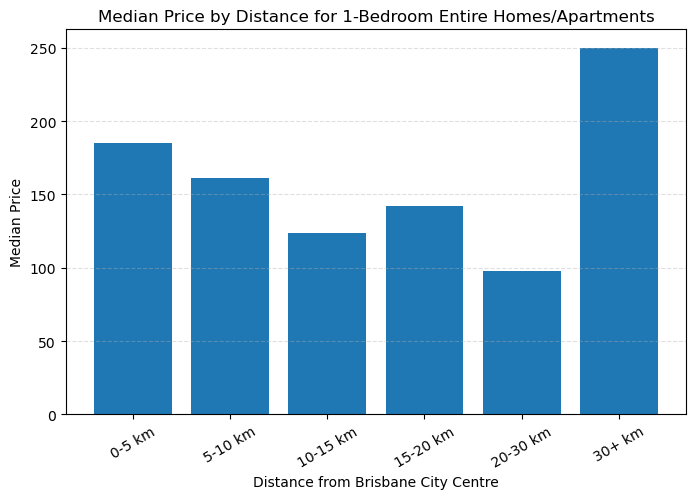

In [96]:
# Plot median price by distance group for one-bedroom entire homes/apartments

plt.figure(figsize=(8, 5))
plt.bar(
    one_bed_distance_price.index.astype(str),
    one_bed_distance_price.values
)

plt.xlabel("Distance from Brisbane City Centre")
plt.ylabel("Median Price")
plt.title("Median Price by Distance for 1-Bedroom Entire Homes/Apartments")
plt.xticks(rotation=30)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.show()

#### 2.4 Amenities by value

In [98]:
# Clean amenities text

train_clean["amenities_clean"] = train_clean["amenities"].astype(str).str.lower()
test_clean["amenities_clean"] = test_clean["amenities"].astype(str).str.lower()

# Convert amenities text into a list of amenities

import ast

def extract_amenities(amenities_text):
    try:
        amenities_list = ast.literal_eval(amenities_text)
        return [str(item).lower().strip() for item in amenities_list]
    except:
        return []

train_clean["amenities_list"] = train_clean["amenities"].apply(extract_amenities)
test_clean["amenities_list"] = test_clean["amenities"].apply(extract_amenities)

In [99]:
# Create a table with one row per listing-amenity pair in training data

amenities_exploded = train_clean[["ID", "price", "amenities_list"]].explode("amenities_list")
amenities_exploded = amenities_exploded.rename(columns={"amenities_list": "amenity"})

# Remove missing/empty amenities
amenities_exploded = amenities_exploded[
    amenities_exploded["amenity"].notna() & 
    (amenities_exploded["amenity"] != "")
]

amenities_exploded.head()

,ID,price,amenity
0,0,97.0,hair dryer
0,0,97.0,hangers
0,0,97.0,fire extinguisher
0,0,97.0,essentials
0,0,97.0,shampoo


In [100]:
# Calculate median price and listing count for each amenity

amenity_price_summary = (
    amenities_exploded
    .groupby("amenity")
    .agg(
        median_price=("price", "median"),
        listing_count=("ID", "count")
    )
    .reset_index()
)

# Keep amenities that appear at least 20 times to avoid unreliable rare amenities
amenity_price_summary = amenity_price_summary[
    amenity_price_summary["listing_count"] >= 20
]

amenity_price_summary.sort_values("median_price", ascending=False).head(20)

,amenity,median_price,listing_count
641,free residential garage on premises – 2 spaces,339.0,32
984,paid parking lot on premises,334.0,25
1296,standalone high chair - always at the listing,282.5,50
374,clothing storage: walk-in closet and wardrobe,279.0,55
347,"children’s books and toys for ages 0-2 years old, 2-5 years old, 5-10 years old, and 10+ years old",275.0,29
475,ev charger,272.0,31
422,crib,271.0,357
965,pack ’n play/travel crib,270.5,190
616,folding or convertible high chair - available upon request,270.0,44
423,crib - always at the listing,268.0,49


In [101]:
# Create low, medium, and high price amenity groups based on median price

low_cutoff = amenity_price_summary["median_price"].quantile(1/3)
high_cutoff = amenity_price_summary["median_price"].quantile(2/3)

def classify_amenity_price(median_price):
    if median_price <= low_cutoff:
        return "low_price_amenity"
    elif median_price <= high_cutoff:
        return "medium_price_amenity"
    else:
        return "high_price_amenity"

amenity_price_summary["amenity_price_group"] = amenity_price_summary["median_price"].apply(classify_amenity_price)

amenity_price_summary["amenity_price_group"].value_counts()

amenity_price_group
medium_price_amenity    78
high_price_amenity      78
low_price_amenity       78
Name: count, dtype: int64

In [102]:
# Create amenity group sets

low_price_amenities = set(
    amenity_price_summary.loc[
        amenity_price_summary["amenity_price_group"] == "low_price_amenity",
        "amenity"
    ]
)

medium_price_amenities = set(
    amenity_price_summary.loc[
        amenity_price_summary["amenity_price_group"] == "medium_price_amenity",
        "amenity"
    ]
)

high_price_amenities = set(
    amenity_price_summary.loc[
        amenity_price_summary["amenity_price_group"] == "high_price_amenity",
        "amenity"
    ]
)

In [103]:
# Count low, medium, and high price amenities for each listing

def count_amenity_group(amenities_list, amenity_group):
    return sum(1 for amenity in amenities_list if amenity in amenity_group)

for df in [train_clean, test_clean]:
    df["low_price_amenities_count"] = df["amenities_list"].apply(
        lambda x: count_amenity_group(x, low_price_amenities)
    )
    
    df["medium_price_amenities_count"] = df["amenities_list"].apply(
        lambda x: count_amenity_group(x, medium_price_amenities)
    )
    
    df["high_price_amenities_count"] = df["amenities_list"].apply(
        lambda x: count_amenity_group(x, high_price_amenities)
    )

In [104]:
# Display examples from each amenity price group

amenity_price_summary.groupby("amenity_price_group").head(4)

,amenity,median_price,listing_count,amenity_price_group
67,50 inch hdtv,203.0,27,medium_price_amenity
80,50 inch hdtv with netflix,243.0,29,high_price_amenity
93,55 inch hdtv,225.0,37,high_price_amenity
112,55 inch hdtv with netflix,202.5,24,medium_price_amenity
183,ac - split type ductless system,201.0,453,medium_price_amenity
197,air conditioning,199.5,2562,medium_price_amenity
232,baby bath,261.0,38,high_price_amenity
238,baby safety gates,260.5,48,high_price_amenity
240,backyard,190.0,453,low_price_amenity
266,beach essentials,194.5,40,low_price_amenity


In [105]:
train_clean[
    [
        "price",
        "low_price_amenities_count",
        "medium_price_amenities_count",
        "high_price_amenities_count"
    ]
].corr()["price"].sort_values(ascending=False)

price                           1.000000
high_price_amenities_count      0.262998
medium_price_amenities_count    0.116163
low_price_amenities_count      -0.059603
Name: price, dtype: float64

/var/folders/wh/mdz_6p0n32s56gk7bktx0zsc0000gn/T/ipykernel_30989/2682464133.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  high_amenity_price = train_clean.groupby("high_amenity_group")["price"].median()


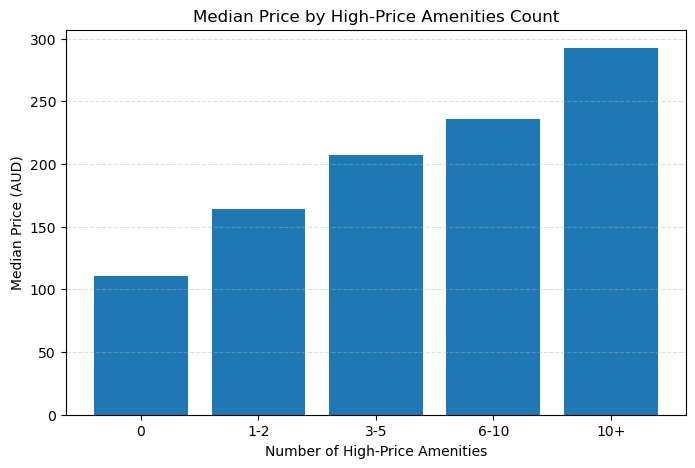

high_amenity_group
0       111.0
1-2     164.0
3-5     207.0
6-10    236.0
10+     292.5
Name: price, dtype: float64

In [106]:
# Group high-price amenities count for easier interpretation

train_clean["high_amenity_group"] = pd.cut(
    train_clean["high_price_amenities_count"],
    bins=[-1, 0, 2, 5, 10, 100],
    labels=["0", "1-2", "3-5", "6-10", "10+"]
)

high_amenity_price = train_clean.groupby("high_amenity_group")["price"].median()

plt.figure(figsize=(8, 5))
plt.bar(high_amenity_price.index.astype(str), high_amenity_price.values)
plt.xlabel("Number of High-Price Amenities")
plt.ylabel("Median Price (AUD)")
plt.title("Median Price by High-Price Amenities Count")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.show()

high_amenity_price

Four feature engineering steps were used. `parking_type` was created from the amenities text to identify whether parking was free, paid, street-based, unavailable, or not stated. `revenue_per_occupied_day` was created by dividing estimated annual revenue by estimated occupancy, providing an approximate revenue per occupied day. `distance_to_city_centre_km` was calculated from latitude and longitude using the Haversine formula to capture location relative to Brisbane CBD.

The amenities column was also transformed into value-based amenity features. Individual amenities were extracted, ranked by the median price of listings containing that amenity, and grouped into low-, medium-, and high-price amenity categories. The number of amenities from each category was then counted for every listing. This is more informative than only counting total amenities because the type of amenity may matter more than the number alone.

<hr style="width:25%;margin-left:0;">     

#### 3. Missing Values (2 marks)

Impute missing values for all selected features.  
- Identify variables with missing values  
- Apply appropriate imputation methods (e.g. mean, median, mode, or other suitable approaches)  
- Ensure that the same imputation strategy is applied consistently to both datasets  
- Briefly explain and justify the method used for different types of variable


In [109]:
features_for_imputation = [
    "host_response_time",
    "host_response_rate",
    "host_acceptance_rate",
    "host_is_superhost",
    "host_listings_count",
    "neighbourhood_cleansed",
    "property_type",
    "room_type",
    "accommodates",
    "bathrooms",
    "bedrooms",
    "beds",
    "minimum_nights",
    "maximum_nights",
    "availability_30",
    "availability_60",
    "availability_90",
    "availability_365",
    "number_of_reviews",
    "number_of_reviews_ltm",
    "number_of_reviews_l30d",
    "review_scores_rating",
    "review_scores_location",
    "review_scores_value",
    "instant_bookable",
    "reviews_per_month",
    "parking_type",
    "revenue_per_occupied_day",
    "distance_to_city_centre_km",
    "low_price_amenities_count",
    "medium_price_amenities_count",
    "high_price_amenities_count"
]

missing_before = pd.DataFrame({
    "Train Missing": train_clean[features_for_imputation].isnull().sum(),
    "Test Missing": test_clean[features_for_imputation].isnull().sum()
})

missing_before = missing_before[
    (missing_before["Train Missing"] > 0) |
    (missing_before["Test Missing"] > 0)
]

missing_before

,Train Missing,Test Missing
host_response_time,287,121
host_response_rate,287,121
host_acceptance_rate,201,78
host_is_superhost,137,56
host_listings_count,2,0
bathrooms,5,0
bedrooms,2,1
beds,3,0
review_scores_rating,437,183
review_scores_location,437,183


#### 3.1 Imputing review features: 

In [111]:
# Rows where some, but not all, selected review features are missing

partial_review_missing = train_clean[
    train_clean[review_cols].isnull().any(axis=1) &
    ~train_clean[review_cols].isnull().all(axis=1)
]

print("Rows where only some selected review features are missing:", partial_review_missing.shape[0])

partial_review_missing[
    ["ID", "number_of_reviews"] + review_cols
].head(10)

Rows where only some selected review features are missing: 0


,ID,number_of_reviews,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value


In [112]:
# Review-related columns to inspect

all_review_cols = [
    "number_of_reviews",
    "number_of_reviews_ltm",
    "number_of_reviews_l30d",
    "reviews_per_month",
    "review_scores_rating",
    "review_scores_accuracy",
    "review_scores_cleanliness",
    "review_scores_checkin",
    "review_scores_communication",
    "review_scores_location",
    "review_scores_value"
]

# Rows where selected review score features are missing

review_missing_rows = train_clean[
    train_clean[["review_scores_rating", "review_scores_location", "review_scores_value", "reviews_per_month"]]
    .isnull()
    .any(axis=1)
]

# Display review information for rows with missing selected review features

review_missing_rows[["ID"] + all_review_cols].head(10)

,ID,number_of_reviews,number_of_reviews_ltm,number_of_reviews_l30d,reviews_per_month,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value
3,3,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,5,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,8,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
17,17,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
18,18,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
20,20,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
21,21,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
39,39,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
46,46,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
56,56,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [113]:
# Review-related selected features

review_impute_cols = [
    "review_scores_rating",
    "review_scores_location",
    "review_scores_value",
    "reviews_per_month"
]

# Convert last_review to datetime if not already converted

train_clean["last_review"] = pd.to_datetime(train_clean["last_review"], errors="coerce")
test_clean["last_review"] = pd.to_datetime(test_clean["last_review"], errors="coerce")

# If a listing has no reviews and no last review date, fill missing review-related values with 0

for col in review_impute_cols:
    train_clean.loc[
        (train_clean["number_of_reviews"] == 0) &
        (train_clean["last_review"].isnull()) &
        (train_clean[col].isnull()),
        col
    ] = 0
    
    test_clean.loc[
        (test_clean["number_of_reviews"] == 0) &
        (test_clean["last_review"].isnull()) &
        (test_clean[col].isnull()),
        col
    ] = 0

In [114]:
# Check remaining missing values in review features

print("Training review missing values after no-review imputation:")
print(train_clean[review_impute_cols].isnull().sum())

print("\nTest review missing values after no-review imputation:")
print(test_clean[review_impute_cols].isnull().sum())

Training review missing values after no-review imputation:
review_scores_rating      0
review_scores_location    0
review_scores_value       0
reviews_per_month         0
dtype: int64

Test review missing values after no-review imputation:
review_scores_rating      0
review_scores_location    0
review_scores_value       0
reviews_per_month         0
dtype: int64


In [115]:
# Create no reviews flag

train_clean["no_reviews_flag"] = (
    (train_clean["number_of_reviews"] == 0) &
    (train_clean["last_review"].isnull())
).astype(int)

test_clean["no_reviews_flag"] = (
    (test_clean["number_of_reviews"] == 0) &
    (test_clean["last_review"].isnull())
).astype(int)

For review-related variables, missing values were treated differently from ordinary numerical missing values. Inspection showed that all **437 rows** with missing selected review features had `number_of_reviews = 0`, and the corresponding `last_review` values were also missing. Other review score fields such as accuracy, cleanliness, check-in, and communication were also unavailable for these rows. This indicates that the missing values were caused by listings having no review history, rather than random missing data.

Therefore, missing values in `review_scores_rating`, `review_scores_location`, `review_scores_value`, and `reviews_per_month` were filled with **0** only when the listing had `number_of_reviews = 0` and no `last_review` date. This represents that the listing has not yet been reviewed.

Because review scores normally have an ordered meaning, where higher values indicate better guest satisfaction, a separate `no_reviews_flag` was also created. This helps distinguish listings that are genuinely unrated from listings with poor review scores. As no related review features were available to estimate these missing values, this rule-based approach was more appropriate than using median imputation.

#### 3.2 Imputing Host response rate and time features: 

In [118]:
response_cols = ["host_response_time", "host_response_rate"]

print("Missing values before imputation:")
print(pd.DataFrame({
    "Train Missing": train_clean[response_cols].isnull().sum(),
    "Test Missing": test_clean[response_cols].isnull().sum()
}))

Missing values before imputation:
                    Train Missing  Test Missing
host_response_time            287           121
host_response_rate            287           121


In [119]:
# Step 1: Same-host imputation
# Use known response behaviour from the same host_id where available.

host_response_rate_map = (
    train_clean
    .dropna(subset=["host_response_rate"])
    .groupby("host_id")["host_response_rate"]
    .median()
)

host_response_time_map = (
    train_clean
    .dropna(subset=["host_response_time"])
    .groupby("host_id")["host_response_time"]
    .agg(lambda x: x.mode().iloc[0] if len(x.mode()) > 0 else np.nan)
)

train_clean["host_response_rate"] = train_clean["host_response_rate"].fillna(
    train_clean["host_id"].map(host_response_rate_map)
)

test_clean["host_response_rate"] = test_clean["host_response_rate"].fillna(
    test_clean["host_id"].map(host_response_rate_map)
)

train_clean["host_response_time"] = train_clean["host_response_time"].fillna(
    train_clean["host_id"].map(host_response_time_map)
)

test_clean["host_response_time"] = test_clean["host_response_time"].fillna(
    test_clean["host_id"].map(host_response_time_map)
)

In [120]:
# Create activity groups using estimated occupancy

def create_activity_group(occupancy):
    if occupancy == 0:
        return "0 occupancy"
    elif occupancy <= 30:
        return "1-30 occupancy"
    elif occupancy <= 90:
        return "31-90 occupancy"
    else:
        return "91+ occupancy"

train_clean["activity_group"] = train_clean["estimated_occupancy_l365d"].apply(create_activity_group)
test_clean["activity_group"] = test_clean["estimated_occupancy_l365d"].apply(create_activity_group)

train_clean["activity_group"].value_counts()

activity_group
91+ occupancy      1503
31-90 occupancy     854
1-30 occupancy      767
0 occupancy         611
Name: count, dtype: int64

In [121]:
# Grouping variables for imputation

group_cols = [
    "activity_group",
    "instant_bookable",
    "host_is_superhost"
]

# Calculate grouped median response rate from training data only

response_rate_group_median = (
    train_clean
    .dropna(subset=["host_response_rate"])
    .groupby(group_cols)["host_response_rate"]
    .median()
)

# Create mapped values as Series, not Index

train_response_rate_impute = pd.Series(
    train_clean.set_index(group_cols).index.map(response_rate_group_median),
    index=train_clean.index
)

test_response_rate_impute = pd.Series(
    test_clean.set_index(group_cols).index.map(response_rate_group_median),
    index=test_clean.index
)

# Fill missing response rate in train and test

train_clean["host_response_rate"] = train_clean["host_response_rate"].fillna(
    train_response_rate_impute
)

test_clean["host_response_rate"] = test_clean["host_response_rate"].fillna(
    test_response_rate_impute
)

In [122]:
# Function to safely calculate mode

def mode_or_nan(x):
    mode_value = x.mode()
    if len(mode_value) > 0:
        return mode_value.iloc[0]
    return np.nan

# Calculate grouped mode response time from training data only

response_time_group_mode = (
    train_clean
    .dropna(subset=["host_response_time"])
    .groupby(group_cols)["host_response_time"]
    .agg(mode_or_nan)
)

# Create mapped values as Series

train_response_time_impute = pd.Series(
    train_clean.set_index(group_cols).index.map(response_time_group_mode),
    index=train_clean.index
)

test_response_time_impute = pd.Series(
    test_clean.set_index(group_cols).index.map(response_time_group_mode),
    index=test_clean.index
)

# Fill missing response time in train and test

train_clean["host_response_time"] = train_clean["host_response_time"].fillna(
    train_response_time_impute
)

test_clean["host_response_time"] = test_clean["host_response_time"].fillna(
    test_response_time_impute
)

In [123]:
response_cols = ["host_response_rate", "host_response_time"]

print("Missing response values after grouped imputation:")
display(pd.DataFrame({
    "Train Missing": train_clean[response_cols].isnull().sum(),
    "Test Missing": test_clean[response_cols].isnull().sum()
}))

Missing response values after grouped imputation:


,Train Missing,Test Missing
host_response_rate,1,4
host_response_time,1,4


In [124]:
# Final fallback using training median/mode

response_rate_median = train_clean["host_response_rate"].median()
response_time_mode = train_clean["host_response_time"].mode()[0]

train_clean["host_response_rate"] = train_clean["host_response_rate"].fillna(response_rate_median)
test_clean["host_response_rate"] = test_clean["host_response_rate"].fillna(response_rate_median)

train_clean["host_response_time"] = train_clean["host_response_time"].fillna(response_time_mode)
test_clean["host_response_time"] = test_clean["host_response_time"].fillna(response_time_mode)

print("Missing response values after final fallback:")
display(pd.DataFrame({
    "Train Missing": train_clean[response_cols].isnull().sum(),
    "Test Missing": test_clean[response_cols].isnull().sum()
}))

Missing response values after final fallback:


,Train Missing,Test Missing
host_response_rate,0,0
host_response_time,0,0


`host_response_rate` and `host_response_time` were imputed together because both variables describe host responsiveness and were missing together in the dataset. Existing 0% response-rate values were treated as valid values and were not overwritten.

Missing `host_response_rate` values were filled using the median response rate from similar listings. Similar listings were defined using `activity_group`, `instant_bookable`, and `host_is_superhost`. This grouping was used because host responsiveness may vary depending on listing activity, whether the listing can be booked instantly, and whether the host is a Superhost.

Missing `host_response_time` values were filled using the most common response-time category within the same groups. Mode was used instead of median because `host_response_time` is categorical. The grouped median and mode values were calculated from the training dataset and then applied consistently to both the training and test datasets.

Any remaining missing values after grouped imputation were filled using the overall training median for `host_response_rate` and the overall training mode for `host_response_time`.

#### 3.3 Acceptance rate

In [127]:
# Check missing host_acceptance_rate before imputation

print("Missing host_acceptance_rate before imputation:")
print("Train:", train_clean["host_acceptance_rate"].isnull().sum())
print("Test:", test_clean["host_acceptance_rate"].isnull().sum())

Missing host_acceptance_rate before imputation:
Train: 201
Test: 78


In [128]:
#### Impute acceptance rate using grouped median
# Grouping variables for acceptance rate imputation

group_cols = [
    "activity_group",
    "instant_bookable",
    "host_is_superhost"
]

# Calculate grouped median acceptance rate from training data only

acceptance_rate_group_median = (
    train_clean
    .dropna(subset=["host_acceptance_rate"])
    .groupby(group_cols)["host_acceptance_rate"]
    .median()
)

# Create mapped values as Series

train_acceptance_rate_impute = pd.Series(
    train_clean.set_index(group_cols).index.map(acceptance_rate_group_median),
    index=train_clean.index
)

test_acceptance_rate_impute = pd.Series(
    test_clean.set_index(group_cols).index.map(acceptance_rate_group_median),
    index=test_clean.index
)

# Fill missing acceptance rate in train and test

train_clean["host_acceptance_rate"] = train_clean["host_acceptance_rate"].fillna(
    train_acceptance_rate_impute
)

test_clean["host_acceptance_rate"] = test_clean["host_acceptance_rate"].fillna(
    test_acceptance_rate_impute
)

In [129]:
# Final fallback using training median

acceptance_rate_median = train_clean["host_acceptance_rate"].median()

train_clean["host_acceptance_rate"] = train_clean["host_acceptance_rate"].fillna(
    acceptance_rate_median
)

test_clean["host_acceptance_rate"] = test_clean["host_acceptance_rate"].fillna(
    acceptance_rate_median
)

In [130]:
# Check missing host_acceptance_rate after imputation

print("Missing host_acceptance_rate after imputation:")
print("Train:", train_clean["host_acceptance_rate"].isnull().sum())
print("Test:", test_clean["host_acceptance_rate"].isnull().sum())

Missing host_acceptance_rate after imputation:
Train: 0
Test: 0


In [131]:
# Show examples where acceptance rate was originally missing in training data

original_acceptance_missing = train["host_acceptance_rate"].isnull()

acceptance_imputation_check = pd.DataFrame({
    "ID": train_clean.loc[original_acceptance_missing, "ID"],
    "activity_group": train_clean.loc[original_acceptance_missing, "activity_group"],
    "instant_bookable": train_clean.loc[original_acceptance_missing, "instant_bookable"],
    "host_is_superhost": train_clean.loc[original_acceptance_missing, "host_is_superhost"],
    "original_acceptance_rate": train.loc[original_acceptance_missing, "host_acceptance_rate"],
    "imputed_acceptance_rate": train_clean.loc[original_acceptance_missing, "host_acceptance_rate"],
    "estimated_occupancy_l365d": train_clean.loc[original_acceptance_missing, "estimated_occupancy_l365d"],
    "estimated_revenue_l365d": train_clean.loc[original_acceptance_missing, "estimated_revenue_l365d"]
})

acceptance_imputation_check.head(5)

,ID,activity_group,instant_bookable,host_is_superhost,original_acceptance_rate,imputed_acceptance_rate,estimated_occupancy_l365d,estimated_revenue_l365d
8,8,0 occupancy,0,0.0,NaN,42.0,0,0.0
21,21,0 occupancy,1,0.0,NaN,99.0,0,0.0
54,54,1-30 occupancy,1,0.0,NaN,99.0,12,3300.0
65,65,0 occupancy,0,0.0,NaN,42.0,0,0.0
68,68,91+ occupancy,0,0.0,NaN,98.0,102,27744.0


`host_acceptance_rate` was imputed separately from response rate and response time because it reflects booking acceptance behaviour rather than communication speed. Existing 0% acceptance-rate values were treated as valid values and were not overwritten.

Missing acceptance rates were filled using the median acceptance rate from similar listings grouped by `activity_group`, `instant_bookable`, and `host_is_superhost`. These variables were used because acceptance behaviour may depend on listing activity, whether guests can book instantly, and whether the host is a Superhost. Grouped median values were calculated from the training dataset and then applied consistently to both the training and test datasets. Any remaining missing values were filled using the overall training median.

#### 3.4 Is superhost

In [134]:
# Check missing values before imputationm

print("Missing host_is_superhost before imputation:")
print("Train:", train_clean["host_is_superhost"].isnull().sum())
print("Test:", test_clean["host_is_superhost"].isnull().sum())

Missing host_is_superhost before imputation:
Train: 137
Test: 56


In [135]:
# Visualise review-related features against host_is_superhost

# Create labels for easier interpretation
superhost_labels = {
    0: "Not Superhost",
    1: "Superhost"
}

# Median values by superhost status
review_by_superhost = train_clean.groupby("host_is_superhost")[
    ["number_of_reviews", "review_scores_rating", "number_of_reviews_ltm"]
].median()

review_by_superhost.index = review_by_superhost.index.map(superhost_labels)

review_by_superhost

,number_of_reviews,review_scores_rating,number_of_reviews_ltm
host_is_superhost,,,
Not Superhost,11.0,4.68,5.0
Superhost,35.0,4.90,17.0


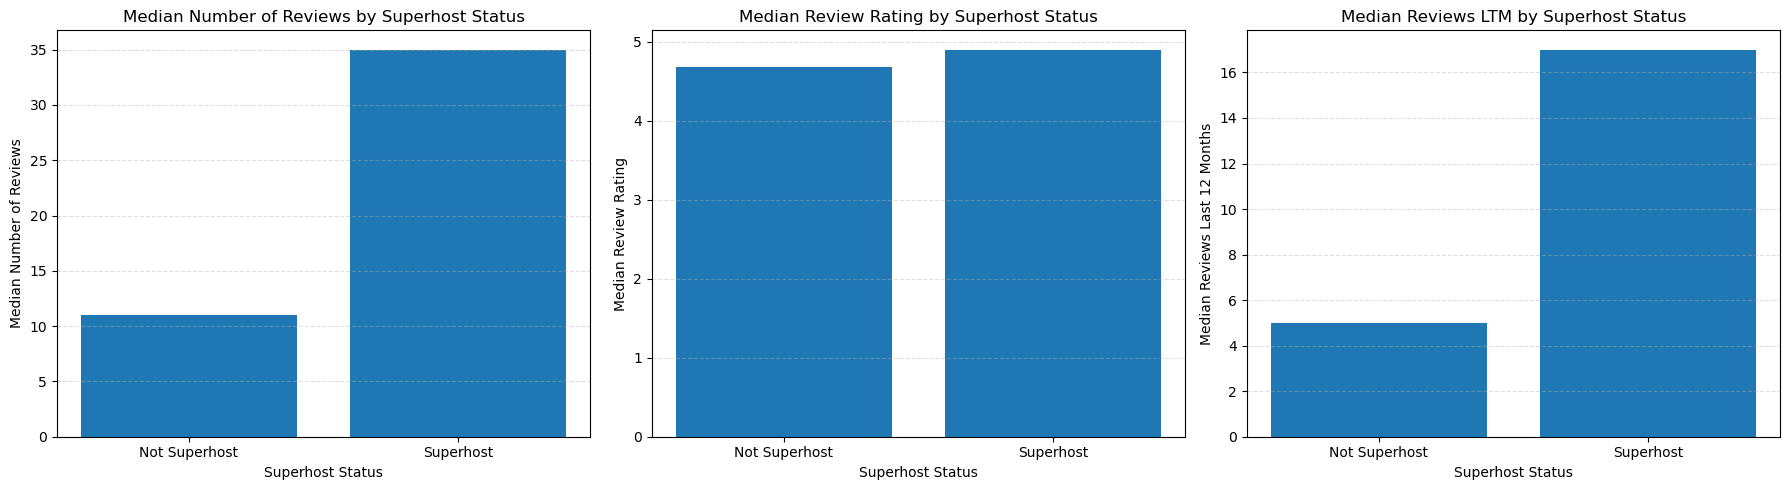

In [136]:
# Plot review-related features by Superhost status

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Number of reviews
axes[0].bar(review_by_superhost.index, review_by_superhost["number_of_reviews"])
axes[0].set_title("Median Number of Reviews by Superhost Status")
axes[0].set_xlabel("Superhost Status")
axes[0].set_ylabel("Median Number of Reviews")
axes[0].grid(axis="y", linestyle="--", alpha=0.4)

# Review score rating
axes[1].bar(review_by_superhost.index, review_by_superhost["review_scores_rating"])
axes[1].set_title("Median Review Rating by Superhost Status")
axes[1].set_xlabel("Superhost Status")
axes[1].set_ylabel("Median Review Rating")
axes[1].grid(axis="y", linestyle="--", alpha=0.4)

# Number of reviews last 12 months
axes[2].bar(review_by_superhost.index, review_by_superhost["number_of_reviews_ltm"])
axes[2].set_title("Median Reviews LTM by Superhost Status")
axes[2].set_xlabel("Superhost Status")
axes[2].set_ylabel("Median Reviews Last 12 Months")
axes[2].grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

In [137]:
# Step 2: Review-based rule for remaining missing values
# Based on the graph, superhosts generally have stronger review activity and high ratings.
# This is only applied where host_is_superhost is still missing.

train_clean.loc[
    train_clean["host_is_superhost"].isnull() &
    (train_clean["number_of_reviews"] >= 30) &
    (train_clean["number_of_reviews_ltm"] >= 10) &
    (train_clean["review_scores_rating"] >= 4.8),
    "host_is_superhost"
] = 1

test_clean.loc[
    test_clean["host_is_superhost"].isnull() &
    (test_clean["number_of_reviews"] >= 30) &
    (test_clean["number_of_reviews_ltm"] >= 10) &
    (test_clean["review_scores_rating"] >= 4.8),
    "host_is_superhost"
] = 1

In [138]:
# Step 3: Remaining missing values are likely not strong superhost cases
# Fill them as 0.

train_clean["host_is_superhost"] = train_clean["host_is_superhost"].fillna(0)
test_clean["host_is_superhost"] = test_clean["host_is_superhost"].fillna(0)

In [139]:
# Check missing values after imputation

print("Missing host_is_superhost after imputation:")
print("Train:", train_clean["host_is_superhost"].isnull().sum())
print("Test:", test_clean["host_is_superhost"].isnull().sum())

print("\nSuperhost value counts after imputation:")
print(train_clean["host_is_superhost"].value_counts())

Missing host_is_superhost after imputation:
Train: 0
Test: 0

Superhost value counts after imputation:
host_is_superhost
0.0    2434
1.0    1301
Name: count, dtype: int64


In [140]:
# Display rows that originally had missing host_is_superhost

affected_superhost_rows = train["host_is_superhost"].isnull()

superhost_imputation_check = pd.DataFrame({
    "ID": train_clean.loc[affected_superhost_rows, "ID"],
    "host_id": train_clean.loc[affected_superhost_rows, "host_id"],
    "original_host_is_superhost": train.loc[affected_superhost_rows, "host_is_superhost"],
    "imputed_host_is_superhost": train_clean.loc[affected_superhost_rows, "host_is_superhost"],
    "number_of_reviews": train_clean.loc[affected_superhost_rows, "number_of_reviews"],
    "number_of_reviews_ltm": train_clean.loc[affected_superhost_rows, "number_of_reviews_ltm"],
    "review_scores_rating": train_clean.loc[affected_superhost_rows, "review_scores_rating"]
})

superhost_imputation_check.head(5)

,ID,host_id,original_host_is_superhost,imputed_host_is_superhost,number_of_reviews,number_of_reviews_ltm,review_scores_rating
20,20,486831290,NaN,0.0,0,0,0.00
55,55,99473754,NaN,0.0,72,22,4.79
104,104,27151351,NaN,0.0,8,8,5.00
116,116,200978182,NaN,0.0,35,8,4.71
199,199,523844737,NaN,1.0,47,47,4.89


`host_is_superhost` was imputed using a rule-based approach based on review activity. Before imputation, Superhosts had noticeably higher median review activity and ratings than non-Superhosts. For example, Superhosts had a higher median number of reviews, higher median review scores, and more reviews in the last 12 months.

Based on this pattern, missing `host_is_superhost` values were filled as `1` only when the listing had strong evidence of Superhost-like behaviour: at least 30 total reviews, at least 10 reviews in the last 12 months, and a review score of at least 4.8. Remaining missing values were filled as `0`, because there was not enough evidence to classify those hosts as Superhosts.

This approach avoids simply filling all missing values with the mode and uses related review-based information to make the imputation more meaningful.

#### 3.5 imputing Bathrooms

In [143]:
# Check missing bathrooms before imputation

print("Missing bathrooms before imputation:")
print("Train:", train_clean["bathrooms"].isnull().sum())
print("Test:", test_clean["bathrooms"].isnull().sum())

Missing bathrooms before imputation:
Train: 5
Test: 0


In [144]:
# Display rows where bathrooms is missing, with bathrooms_text

print("Training rows with missing bathrooms:")
display(train_clean.loc[
    train_clean["bathrooms"].isnull(),
    ["ID", "bathrooms", "bathrooms_text", "bedrooms", "beds", "accommodates", "room_type", "property_type"]
])

print("Test rows with missing bathrooms:")
display(test_clean.loc[
    test_clean["bathrooms"].isnull(),
    ["ID", "bathrooms", "bathrooms_text", "bedrooms", "beds", "accommodates", "room_type", "property_type"]
])

Training rows with missing bathrooms:


,ID,bathrooms,bathrooms_text,bedrooms,beds,accommodates,room_type,property_type
287,287,NaN,NaN,1.0,1.0,2,Private room,Private room in home
314,314,NaN,NaN,1.0,1.0,2,Private room,Private room in rental unit
679,679,NaN,NaN,1.0,2.0,2,Private room,Private room in home
1706,1706,NaN,NaN,4.0,4.0,8,Entire home/apt,Entire home
3281,3281,NaN,NaN,1.0,1.0,1,Private room,Private room in home


Test rows with missing bathrooms:


,ID,bathrooms,bathrooms_text,bedrooms,beds,accommodates,room_type,property_type


In [145]:
# Function to extract a short snippet around bathroom-related words from description

def bathroom_description_snippet(text, window=8):
    text = str(text)
    words = text.split()
    
    bathroom_keywords = ["bathroom", "bathrooms", "bath", "baths"]
    
    for i, word in enumerate(words):
        clean_word = word.lower().strip(".,;:!?()[]{}")
        
        if clean_word in bathroom_keywords:
            start = max(i - window, 0)
            end = min(i + window + 1, len(words))
            return " ".join(words[start:end])
    
    return "No bathroom text found"


# Create temporary bathroom snippet columns

train_clean["bathroom_description_snippet"] = train_clean["description"].apply(bathroom_description_snippet)
test_clean["bathroom_description_snippet"] = test_clean["description"].apply(bathroom_description_snippet)


# Display rows where bathrooms is missing, with bathrooms_text and description snippet

print("Training rows with missing bathrooms:")
display(train_clean.loc[
    train_clean["bathrooms"].isnull(),
    [
        "ID", "bathrooms", "bathrooms_text", "bathroom_description_snippet",
        "bedrooms", "beds", "accommodates", "room_type", "property_type"
    ]
])

print("Test rows with missing bathrooms:")
display(test_clean.loc[
    test_clean["bathrooms"].isnull(),
    [
        "ID", "bathrooms", "bathrooms_text", "bathroom_description_snippet",
        "bedrooms", "beds", "accommodates", "room_type", "property_type"
    ]
])

Training rows with missing bathrooms:


,ID,bathrooms,bathrooms_text,bathroom_description_snippet,bedrooms,beds,accommodates,room_type,property_type
287,287,NaN,NaN,No bathroom text found,1.0,1.0,2,Private room,Private room in home
314,314,NaN,NaN,No bathroom text found,1.0,1.0,2,Private room,Private room in rental unit
679,679,NaN,NaN,"get 20% off! Price is per room. Shared bathroom, kitchen, and living areas.each room has maximum 2",1.0,2.0,2,Private room,Private room in home
1706,1706,NaN,NaN,"families or groups. Featuring four bedrooms and two bathrooms, it offers bright, clean interiors and a private",4.0,4.0,8,Entire home/apt,Entire home
3281,3281,NaN,NaN,<br />There is private parking available <br />Private bathroom <br />Nice lounge area <br />Have all amenities<br,1.0,1.0,1,Private room,Private room in home


Test rows with missing bathrooms:


,ID,bathrooms,bathrooms_text,bathroom_description_snippet,bedrooms,beds,accommodates,room_type,property_type


In [146]:
# Manually fill bathrooms where description clearly gives bathroom information

train_clean.loc[train_clean["ID"] == 679, "bathrooms"] = 1
train_clean.loc[train_clean["ID"] == 1706, "bathrooms"] = 2
train_clean.loc[train_clean["ID"] == 3281, "bathrooms"] = 1

In [147]:
# Fill remaining missing bathrooms using median of similar listings

bathroom_group_median = (
    train_clean
    .groupby(["room_type", "bedrooms", "accommodates"])["bathrooms"]
    .median()
)

def impute_bathrooms(row):
    if pd.notna(row["bathrooms"]):
        return row["bathrooms"]
    
    key = (row["room_type"], row["bedrooms"], row["accommodates"])
    
    if key in bathroom_group_median.index:
        return bathroom_group_median.loc[key]
    
    return train_clean["bathrooms"].median()

train_clean["bathrooms"] = train_clean.apply(impute_bathrooms, axis=1)
test_clean["bathrooms"] = test_clean.apply(impute_bathrooms, axis=1)

In [148]:
print("Missing bathrooms after imputation:")
print("Train:", train_clean["bathrooms"].isnull().sum())
print("Test:", test_clean["bathrooms"].isnull().sum())

Missing bathrooms after imputation:
Train: 0
Test: 0


For missing `bathrooms` values, `bathrooms_text` was checked first because it often contains bathroom information in text form. However, for the missing bathroom rows, `bathrooms_text` was also missing. Therefore, the listing descriptions were inspected for bathroom-related text. Where the description clearly mentioned the bathroom count or type, the value was manually filled using that listing-specific information.

For the remaining missing bathroom values, median imputation was applied using similar listings based on `room_type`, `bedrooms`, and `accommodates`. This is more appropriate than using the overall median because bathroom count is related to property size and listing type. The same grouped median logic was applied to both training and test datasets.

#### 3.6 Bedrooms

In [151]:
# Check bedrooms before imputation

print("Training bedrooms missing:", train_clean["bedrooms"].isnull().sum())
print("Training bedrooms = 0:", (train_clean["bedrooms"] == 0).sum())

print("\nTest bedrooms missing:", test_clean["bedrooms"].isnull().sum())
print("Test bedrooms = 0:", (test_clean["bedrooms"] == 0).sum())

Training bedrooms missing: 2
Training bedrooms = 0: 89

Test bedrooms missing: 1
Test bedrooms = 0: 44


In [152]:
# Create bedroom mode by accommodates and beds from training data
# Use only rows where bedrooms is greater than 0 to learn normal bedroom values.

bedroom_mode_by_capacity = (
    train_clean[train_clean["bedrooms"] > 0]
    .groupby(["accommodates", "beds"])["bedrooms"]
    .agg(lambda x: x.mode().iloc[0] if len(x.mode()) > 0 else np.nan)
)

# Overall bedroom mode from training data, excluding 0 values

bedroom_overall_mode = train_clean.loc[train_clean["bedrooms"] > 0, "bedrooms"].mode()[0]


# Impute bedrooms where bedrooms is missing or suspiciously 0

def impute_bedrooms(row):
    if pd.notna(row["bedrooms"]) and row["bedrooms"] != 0:
        return row["bedrooms"]
    
    key = (row["accommodates"], row["beds"])
    
    if key in bedroom_mode_by_capacity.index:
        return bedroom_mode_by_capacity.loc[key]
    
    return bedroom_overall_mode


train_clean["bedrooms"] = train_clean.apply(impute_bedrooms, axis=1)
test_clean["bedrooms"] = test_clean.apply(impute_bedrooms, axis=1)

In [153]:
print("Training bedrooms missing after imputation:", train_clean["bedrooms"].isnull().sum())
print("Training bedrooms = 0 after imputation:", (train_clean["bedrooms"] == 0).sum())

print("\nTest bedrooms missing after imputation:", test_clean["bedrooms"].isnull().sum())
print("Test bedrooms = 0 after imputation:", (test_clean["bedrooms"] == 0).sum())

Training bedrooms missing after imputation: 0
Training bedrooms = 0 after imputation: 0

Test bedrooms missing after imputation: 0
Test bedrooms = 0 after imputation: 0


Missing and suspicious `0` values in `bedrooms` were treated as invalid because a listing with beds and accommodation capacity should normally have at least one bedroom. To impute these values, the training data was grouped by `accommodates` and `beds`, and the mode bedroom value from similar listings was used. Only valid bedroom values greater than 0 were used to learn the mode, so the imputation was not influenced by suspicious zero-bedroom records. If no matching group was available, the overall bedroom mode from the training data was used as a fallback. The same training-based rules were then applied to both the training and test datasets.

#### 3.7 imputing missing Beds

In [156]:
# Check beds before imputation

print("Training beds missing:", train_clean["beds"].isnull().sum())
print("Training beds = 0:", (train_clean["beds"] == 0).sum())

print("\nTest beds missing:", test_clean["beds"].isnull().sum())
print("Test beds = 0:", (test_clean["beds"] == 0).sum())

Training beds missing: 3
Training beds = 0: 43

Test beds missing: 0
Test beds = 0: 18


In [157]:
# Create beds mode by accommodates and bedrooms from training data
# Use only rows where beds is greater than 0 to learn normal bed values.

beds_mode_by_capacity = (
    train_clean[train_clean["beds"] > 0]
    .groupby(["accommodates", "bedrooms"])["beds"]
    .agg(lambda x: x.mode().iloc[0] if len(x.mode()) > 0 else np.nan)
)

# Overall beds mode from training data, excluding 0 values

beds_overall_mode = train_clean.loc[train_clean["beds"] > 0, "beds"].mode()[0]

In [158]:
# Impute beds where beds is missing or suspiciously 0

def impute_beds(row):
    if pd.notna(row["beds"]) and row["beds"] != 0:
        return row["beds"]
    
    key = (row["accommodates"], row["bedrooms"])
    
    if key in beds_mode_by_capacity.index:
        return beds_mode_by_capacity.loc[key]
    
    return beds_overall_mode


train_clean["beds"] = train_clean.apply(impute_beds, axis=1)
test_clean["beds"] = test_clean.apply(impute_beds, axis=1)

In [159]:
# Check beds after imputation

print("Training beds missing after imputation:", train_clean["beds"].isnull().sum())
print("Training beds = 0 after imputation:", (train_clean["beds"] == 0).sum())

print("\nTest beds missing after imputation:", test_clean["beds"].isnull().sum())
print("Test beds = 0 after imputation:", (test_clean["beds"] == 0).sum())

Training beds missing after imputation: 0
Training beds = 0 after imputation: 0

Test beds missing after imputation: 0
Test beds = 0 after imputation: 0


In [160]:
# Display examples of bed changes for original 0.0 and missing values

# Rows originally having beds = 0
original_zero_beds = train["beds"] == 0

zero_bed_changes = pd.DataFrame({
    "ID": train_clean.loc[original_zero_beds, "ID"],
    "original_beds": train.loc[original_zero_beds, "beds"],
    "imputed_beds": train_clean.loc[original_zero_beds, "beds"],
    "bedrooms": train_clean.loc[original_zero_beds, "bedrooms"],
    "accommodates": train_clean.loc[original_zero_beds, "accommodates"],
    "room_type": train_clean.loc[original_zero_beds, "room_type"],
    "property_type": train_clean.loc[original_zero_beds, "property_type"]
})

print("Examples where original beds = 0:")
display(zero_bed_changes.head(2))


# Rows originally having beds missing
original_missing_beds = train["beds"].isnull()

missing_bed_changes = pd.DataFrame({
    "ID": train_clean.loc[original_missing_beds, "ID"],
    "original_beds": train.loc[original_missing_beds, "beds"],
    "imputed_beds": train_clean.loc[original_missing_beds, "beds"],
    "bedrooms": train_clean.loc[original_missing_beds, "bedrooms"],
    "accommodates": train_clean.loc[original_missing_beds, "accommodates"],
    "room_type": train_clean.loc[original_missing_beds, "room_type"],
    "property_type": train_clean.loc[original_missing_beds, "property_type"]
})

print("Examples where original beds were missing:")
display(missing_bed_changes.head(2))

Examples where original beds = 0:


,ID,original_beds,imputed_beds,bedrooms,accommodates,room_type,property_type
6,6,0.0,3.0,3.0,6,Entire home/apt,Entire rental unit
99,99,0.0,1.0,1.0,2,Private room,Private room in home


Examples where original beds were missing:


,ID,original_beds,imputed_beds,bedrooms,accommodates,room_type,property_type
969,969,NaN,1.0,1.0,1,Private room,Private room in rental unit
2613,2613,NaN,1.0,1.0,1,Entire home/apt,Entire guesthouse


Missing and suspicious `0` values in `beds` were also treated as invalid because listings with accommodation capacity should generally have at least one bed. Beds were imputed using the mode value from similar listings grouped by `accommodates` and `bedrooms`. This approach was used because the number of beds is closely related to both the number of guests a listing can accommodate and the number of bedrooms. Only valid bed values greater than 0 were used to calculate the grouped mode. If no matching group was available, the overall beds mode from the training data was used as a fallback. The same imputation logic was applied consistently to both datasets.

#### 3.8 imputing missing Host listings count

In [163]:
# Check missing host_listings_count before imputation

print("Missing host_listings_count before imputation:")
print("Train:", train_clean["host_listings_count"].isnull().sum())
print("Test:", test_clean["host_listings_count"].isnull().sum())

Missing host_listings_count before imputation:
Train: 2
Test: 0


In [164]:
# Create host listing counts based on how many times each host_id appears
# Combine train and test so the count reflects all available listings in this assignment dataset

combined_host_ids = pd.concat([
    train_clean["host_id"],
    test_clean["host_id"]
])

host_id_counts = combined_host_ids.value_counts()

In [165]:
# Fill missing host_listings_count using the number of times the host appears in train + test

train_clean["host_listings_count"] = train_clean["host_listings_count"].fillna(
    train_clean["host_id"].map(host_id_counts)
)

test_clean["host_listings_count"] = test_clean["host_listings_count"].fillna(
    test_clean["host_id"].map(host_id_counts)
)

In [166]:
# Check missing host_listings_count after imputation

print("Missing host_listings_count after imputation:")
print("Train:", train_clean["host_listings_count"].isnull().sum())
print("Test:", test_clean["host_listings_count"].isnull().sum())

Missing host_listings_count after imputation:
Train: 0
Test: 0


In [167]:
features_for_imputation = [
    "host_response_time",
    "host_response_rate",
    "host_acceptance_rate",
    "host_is_superhost",
    "host_listings_count",
    "neighbourhood_cleansed",
    "property_type",
    "room_type",
    "accommodates",
    "bathrooms",
    "bedrooms",
    "beds",
    "minimum_nights",
    "maximum_nights",
    "availability_30",
    "availability_60",
    "availability_90",
    "availability_365",
    "number_of_reviews",
    "number_of_reviews_ltm",
    "number_of_reviews_l30d",
    "review_scores_rating",
    "review_scores_location",
    "review_scores_value",
    "instant_bookable",
    "reviews_per_month",
    "parking_type",
    "revenue_per_occupied_day",
    "distance_to_city_centre_km",
    "low_price_amenities_count",
    "medium_price_amenities_count",
    "high_price_amenities_count"
]

missing_before = pd.DataFrame({
    "Train Missing": train_clean[features_for_imputation].isnull().sum(),
    "Test Missing": test_clean[features_for_imputation].isnull().sum()
})

missing_before = missing_before[
    (missing_before["Train Missing"] > 0) |
    (missing_before["Test Missing"] > 0)
]

missing_before

,Train Missing,Test Missing


<hr style="width:25%;margin-left:0;">   

#### 4. Encoding Categorical Variables (2 marks)

Encode all categorical variables appropriately.  
- Identify all categorical features in the dataset  
- For features with more than 5 unique values, retain the 5 most frequent categories and group the remaining values into an "other" category  
- Apply an appropriate encoding method, i.e. ordinal vs. nominal  
- Ensure that encoding is applied consistently to both the training and test datasets  
- Briefly explain your encoding choices


In [169]:
# Identify categorical variables to encode

categorical_features = [
    "host_response_time",
    "neighbourhood_cleansed",
    "property_type",
    "room_type",
    "parking_type"
]

categorical_unique_examples = pd.DataFrame({
    "Train Unique Count": train_clean[categorical_features].nunique(),
    "Test Unique Count": test_clean[categorical_features].nunique(),
    "Train Example Values": [
        train_clean[col].dropna().unique()[:5] for col in categorical_features
    ],
    "Test Example Values": [
        test_clean[col].dropna().unique()[:5] for col in categorical_features
    ]
})

categorical_unique_examples

,Train Unique Count,Test Unique Count,Train Example Values,Test Example Values
host_response_time,4,4,"[within an hour, within a day, within a few hours, a few days or more]","[within an hour, within a day, within a few hours, a few days or more]"
neighbourhood_cleansed,132,119,"[Rocklea - Acacia Ridge, Wynnum, Fortitude Valley, Newstead - Bowen Hills, West End]","[Brisbane City, Spring Hill, Fortitude Valley, Auchenflower, Eagle Farm - Pinkenba]"
property_type,41,36,"[Entire rental unit, Entire guest suite, Private room in rental unit, Entire home, Private room in townhouse]","[Entire rental unit, Private room in home, Entire home, Private room in rental unit, Entire guest suite]"
room_type,4,3,"[Entire home/apt, Private room, Hotel room, Shared room]","[Entire home/apt, Private room, Hotel room]"
parking_type,6,6,"[Free parking, Free street parking, Not stated, Paid parking, Parking available]","[Free parking, Paid parking, Free street parking, Not stated, Parking available]"


In [170]:
# Combine similar parking categories before encoding

train_clean["parking_type"] = train_clean["parking_type"].replace({
    "Free parking": "Free street parking",
    "Free street parking": "Free street parking"
})

test_clean["parking_type"] = test_clean["parking_type"].replace({
    "Free parking": "Free street parking",
    "Free street parking": "Free street parking"
})

In [171]:
# High-cardinality categorical variables

high_cardinality_features = [
    "neighbourhood_cleansed",
    "property_type"
]

def keep_top_5_categories(train_df, test_df, column):
    top_5 = train_df[column].value_counts().head(5).index
    
    train_df[column] = train_df[column].where(train_df[column].isin(top_5), "Other")
    test_df[column] = test_df[column].where(test_df[column].isin(top_5), "Other")
    
    return list(top_5)

top_5_category_dict = {}

for col in high_cardinality_features:
    top_5_category_dict[col] = keep_top_5_categories(train_clean, test_clean, col)

top_5_category_dict

{'neighbourhood_cleansed': ['Brisbane City',
  'South Brisbane',
  'Fortitude Valley',
  'Newstead - Bowen Hills',
  'Spring Hill'],
 'property_type': ['Entire rental unit',
  'Entire home',
  'Private room in home',
  'Private room in rental unit',
  'Entire guest suite']}

In [172]:
# Check category counts after grouping

for col in categorical_features:
    print(f"\n{col}")
    print(train_clean[col].value_counts())


host_response_time
host_response_time
within an hour        3166
within a few hours     320
within a day           181
a few days or more      68
Name: count, dtype: int64

neighbourhood_cleansed
neighbourhood_cleansed
Other                     2298
Brisbane City              567
South Brisbane             314
Fortitude Valley           277
Newstead - Bowen Hills     149
Spring Hill                130
Name: count, dtype: int64

property_type
property_type
Entire rental unit             1804
Entire home                     596
Private room in home            513
Other                           504
Private room in rental unit     196
Entire guest suite              122
Name: count, dtype: int64

room_type
room_type
Entire home/apt    2854
Private room        875
Shared room           4
Hotel room            2
Name: count, dtype: int64

parking_type
parking_type
Free street parking    2737
Not stated              621
Paid parking            318
Paid street parking      31
Parking availab

Before encoding, similar parking categories were combined. `Free parking` and `Free street parking` were grouped together because both indicate that guests have access to free parking. This reduces unnecessary category splitting.

The top-five category rule was applied only to high-cardinality categorical variables, specifically `neighbourhood_cleansed` and `property_type`. These variables had many unique categories, so the five most frequent categories in the training dataset were retained and all remaining categories were grouped as `Other`. The same grouping rules were applied to the test dataset to keep train and test preparation consistent.

Categorical variables with five or fewer categories, such as `host_response_time`, `room_type`, and  `parking_type` were kept as they were because they already had a manageable number of categories.

#### Ordinal encoding

In [175]:
# Ordinal encoding for host_response_time

host_response_order = {
    "a few days or more": 1,
    "within a day": 2,
    "within a few hours": 3,
    "within an hour": 4
}

train_clean["host_response_time_encoded"] = train_clean["host_response_time"].map(host_response_order)
test_clean["host_response_time_encoded"] = test_clean["host_response_time"].map(host_response_order)

In [176]:
# Nominal categorical variables for one-hot encoding

nominal_features = [
    "neighbourhood_cleansed",
    "property_type",
    "room_type",
    "parking_type"
]

train_encoded_nominal = pd.get_dummies(
    train_clean[nominal_features],
    prefix=nominal_features,
    drop_first=True
)

test_encoded_nominal = pd.get_dummies(
    test_clean[nominal_features],
    prefix=nominal_features,
    drop_first=True
)

test_encoded_nominal = test_encoded_nominal.reindex(
    columns=train_encoded_nominal.columns,
    fill_value=0
)

In [177]:
numeric_and_binary_features = [
    "host_response_rate",
    "host_acceptance_rate",
    "host_is_superhost",
    "host_listings_count",
    "accommodates",
    "bathrooms",
    "bedrooms",
    "beds",
    "minimum_nights",
    "maximum_nights",
    "availability_30",
    "availability_60",
    "availability_90",
    "availability_365",
    "number_of_reviews",
    "number_of_reviews_ltm",
    "number_of_reviews_l30d",
    "review_scores_rating",
    "review_scores_location",
    "review_scores_value",
    "instant_bookable",
    "reviews_per_month",
    "distance_to_city_centre_km",
    "revenue_per_occupied_day",
    "no_reviews_flag",
    "low_price_amenities_count",
    "medium_price_amenities_count",
    "high_price_amenities_count",
    "host_response_time_encoded"
]

X_train_encoded = pd.concat(
    [train_clean[numeric_and_binary_features], train_encoded_nominal],
    axis=1
)

X_test_encoded = pd.concat(
    [test_clean[numeric_and_binary_features], test_encoded_nominal],
    axis=1
)

y_train = train_clean["price"]

In [178]:
print("Final encoded training shape:", X_train_encoded.shape)
print("Final encoded test shape:", X_test_encoded.shape)

print("Missing values in X_train_encoded:", X_train_encoded.isnull().sum().sum())
print("Missing values in X_test_encoded:", X_test_encoded.isnull().sum().sum())

Final encoded training shape: (3735, 46)
Final encoded test shape: (1601, 46)
Missing values in X_train_encoded: 0
Missing values in X_test_encoded: 0


`host_response_time` was encoded using ordinal encoding because the response-time categories have a natural order, from slowest response to fastest response.

Nominal categorical variables such as `neighbourhood_cleansed`, `property_type`, `room_type`, and `parking_type` were encoded using one-hot encoding because these categories do not have a natural ranking. For example, one neighbourhood or property type is not naturally higher or lower than another.

Before one-hot encoding, high-cardinality variables such as `neighbourhood_cleansed` and `property_type` were reduced by keeping the five most frequent categories in the training dataset and grouping all remaining categories as `Other`. The same grouping rules were applied to the test dataset to ensure consistency.

The final modelling dataset included the engineered features created in Task 2: `parking_type`, `revenue_per_occupied_day`, `distance_to_city_centre_km`, and the low-, medium-, and high-price amenity count features.

<hr style="width:25%;margin-left:0;">   

#### 5. Additional Data Preparation (2 marks)

Perform any additional data preparation steps required before building predictive models.  
- Consider steps such as scaling, transformations, or handling outliers  
- Ensure that any transformations are applied consistently to both the training and test datasets  
- Clearly describe each step you perform  
- Briefly justify why these steps are necessary


In [181]:
# Check price distribution before transformation

train_clean["price"].describe()
# Calculate selected price percentiles

price_percentiles = train_clean["price"].quantile([0.01, 0.05, 0.50, 0.95, 0.99])
price_percentiles

0.01     51.00
0.05     68.00
0.50    193.00
0.95    511.60
0.99    959.24
Name: price, dtype: float64

In [182]:
# Cap extreme price values at the 99th percentile

price_cap = train_clean["price"].quantile(0.99)

train_clean["price_capped"] = train_clean["price"].clip(upper=price_cap)

print("99th percentile price cap:", price_cap)

train_clean[["price", "price_capped"]].describe()

99th percentile price cap: 959.239999999998


,price,price_capped
count,3735.000000,3735.000000
mean,230.082463,225.646083
std,194.648174,153.620908
min,36.000000,36.000000
25%,129.000000,129.000000
50%,193.000000,193.000000
75%,267.000000,267.000000
max,5000.000000,959.240000


In [183]:
# Log transform the capped price target

train_clean["log_price"] = np.log1p(train_clean["price_capped"])

train_clean[["price", "price_capped", "log_price"]].head()

,price,price_capped,log_price
0,97.0,97.0,4.584967
1,205.0,205.0,5.327876
2,186.0,186.0,5.231109
3,157.0,157.0,5.062595
4,300.0,300.0,5.707110


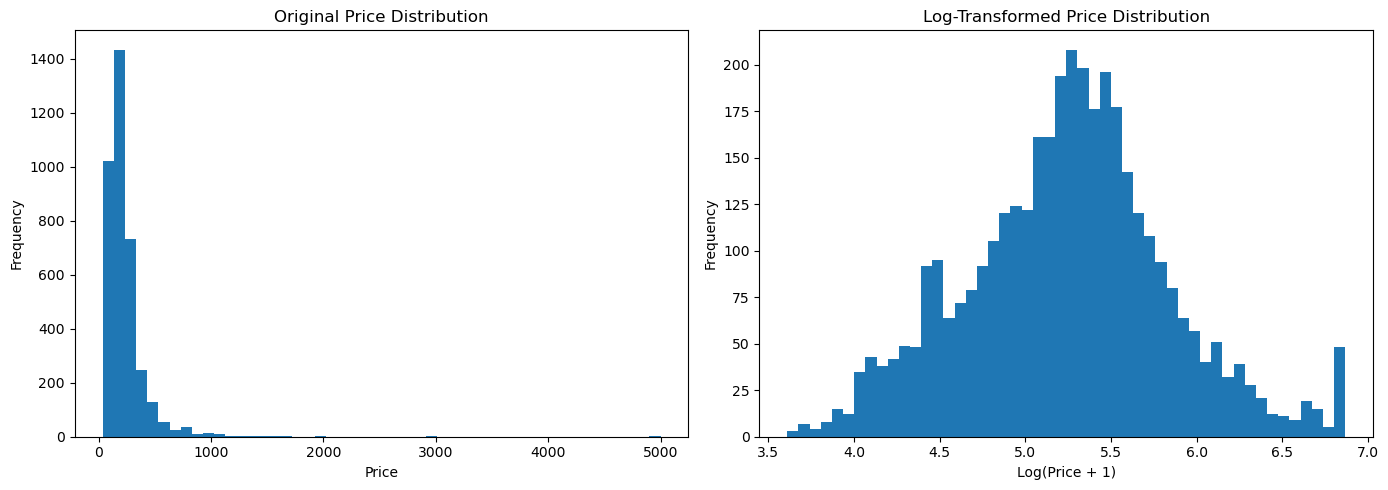

In [184]:
# Compare original and log-transformed price distributions

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(train_clean["price"], bins=50)
axes[0].set_title("Original Price Distribution")
axes[0].set_xlabel("Price")
axes[0].set_ylabel("Frequency")

axes[1].hist(train_clean["log_price"], bins=50)
axes[1].set_title("Log-Transformed Price Distribution")
axes[1].set_xlabel("Log(Price + 1)")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

In [185]:
from sklearn.preprocessing import StandardScaler

# Create copies for scaled modelling data

X_train_prepared = X_train_encoded.copy()
X_test_prepared = X_test_encoded.copy()

# Scale all encoded numeric columns using training data only

scaler = StandardScaler()

X_train_prepared[X_train_prepared.columns] = scaler.fit_transform(X_train_prepared)
X_test_prepared[X_test_prepared.columns] = scaler.transform(X_test_prepared)

# Target variable for modelling

y_train_prepared = train_clean["log_price"]

In [186]:
print("Prepared training data shape:", X_train_prepared.shape)
print("Prepared test data shape:", X_test_prepared.shape)

print("Missing values in prepared training data:", X_train_prepared.isnull().sum().sum())
print("Missing values in prepared test data:", X_test_prepared.isnull().sum().sum())

Prepared training data shape: (3735, 46)
Prepared test data shape: (1601, 46)
Missing values in prepared training data: 0
Missing values in prepared test data: 0


In [187]:
X_train_prepared.head()

,host_response_rate,host_acceptance_rate,host_is_superhost,host_listings_count,accommodates,bathrooms,bedrooms,beds,minimum_nights,maximum_nights,...,property_type_Other,property_type_Private room in home,property_type_Private room in rental unit,room_type_Hotel room,room_type_Private room,room_type_Shared room,parking_type_Not stated,parking_type_Paid parking,parking_type_Paid street parking,parking_type_Parking available
0,0.254912,0.071115,1.367797,-0.375924,-0.737596,-0.600983,-0.723643,-0.726254,0.065399,-0.148941,...,-0.394954,-0.399021,-0.235336,-0.023147,-0.553122,-0.032743,-0.446567,-0.305064,-0.091484,-0.08691
1,0.254912,0.244604,1.367797,-0.438515,0.128731,-0.600983,0.200393,0.551146,-0.196128,-1.098123,...,-0.394954,-0.399021,-0.235336,-0.023147,-0.553122,-0.032743,-0.446567,-0.305064,-0.091484,-0.08691
2,0.254912,0.548212,-0.731103,-0.384865,-0.737596,-0.600983,-0.723643,-0.726254,-0.196128,-0.148941,...,-0.394954,-0.399021,-0.235336,-0.023147,-0.553122,-0.032743,2.239306,-0.305064,-0.091484,-0.08691
3,0.254912,0.548212,-0.731103,-0.438515,-0.737596,-0.600983,-0.723643,-0.087554,1.111510,0.838101,...,-0.394954,-0.399021,-0.235336,-0.023147,-0.553122,-0.032743,-0.446567,3.278000,-0.091484,-0.08691
4,0.254912,0.418094,1.367797,0.938502,0.995059,0.817002,1.124430,0.551146,0.196163,-0.148941,...,-0.394954,-0.399021,-0.235336,-0.023147,-0.553122,-0.032743,2.239306,-0.305064,-0.091484,-0.08691


The `price` variable was highly right-skewed, with a small number of very high-price listings. To reduce the effect of extreme values, prices were capped at the 99th percentile. This prevents a small number of unusual listings from having too much influence on the model.

After capping, a log transformation was applied to the target variable using `log(price + 1)`. This helps reduce skewness and makes the price distribution more balanced for modelling.

Feature scaling was also applied using `StandardScaler`. The scaler was fitted on the training data and then applied to both the training and test datasets. This ensures consistency and avoids using information from the test dataset during preparation. Scaling is useful because selected variables have different ranges, such as availability days, review counts, distances, and encoded features.

After these preparation steps, the final training and test feature matrices were checked to confirm that there were no missing values remaining.

---- Add your written answer here ------

---
---
## Task 3: Model Fitting, Tuning, and Prediction

**Total Marks: 10**

- Use the dataset obtained from **Task 2** for this task.  
- Do not create any new features. You must rely only on the variables constructed in Task 2.  
- Ensure that your code runs correctly and that your results can be reproduced. Your submitted forecasts must be generated directly from your code.



Student in charge of this task: `(insert name here)`

<hr style="width:25%;margin-left:0;">   

#### 1. Initial Model Set (2 marks)

Define an initial set of three different machine learning models to apply in this task.  
- Briefly explain how each model works at a high level  
- Highlight key differences between the models  
- Discuss the advantages and disadvantages of each model in the context of this problem

### 1. Initial Model Set

Three models were selected for the initial Airbnb price prediction task: Ridge Regression, Decision Tree Regressor, and Random Forest Regressor.

Ridge Regression was used as the linear baseline model. It estimates a linear relationship between the selected features and price, while using regularisation to reduce overfitting. Its main advantage is that it is simple, fast, and easy to interpret. However, it may underfit because Airbnb prices are affected by non-linear relationships between property size, room type, location, amenities, and reviews.

Decision Tree Regressor works by splitting the data into smaller groups based on feature values. It can capture non-linear relationships and interactions between variables, such as the combined effect of room type and number of bedrooms. However, a single decision tree can overfit if it becomes too deep.

Random Forest Regressor is an ensemble model that builds many decision trees and averages their predictions. This usually makes it more stable and accurate than a single decision tree. It is suitable for this problem because Airbnb pricing is likely influenced by complex interactions between location, property characteristics, amenities, and review behaviour. Its main disadvantage is that it is less interpretable and more computationally expensive than simpler models.

The key difference between these models is model complexity. Ridge Regression is simple and linear, Decision Tree is flexible but more prone to overfitting, and Random Forest is more robust because it combines many trees.

<hr style="width:25%;margin-left:0;"> 

#### 2. Model Evaluation Strategy (2 marks)

Describe how you will train and evaluate your models.  
- Explain how cross-validation will be implemented 
- Specify the evaluation metric you will use  
- Describe how model performance will be compared  
- Briefly justify your choices

### 2. Model Evaluation Strategy

The models were evaluated using 5-fold cross-validation. This approach divides the training data into five parts. In each round, four parts are used for training and one part is used for validation. This process is repeated five times so that every part is used once as the validation set.

The evaluation metric used was Mean Absolute Percentage Error (MAPE), which is the Kaggle competition metric. MAPE measures the average percentage difference between the actual and predicted Airbnb prices. A lower MAPE indicates better model performance.

The models were compared using their average cross-validated MAPE. The model with the lowest MAPE was selected as the best initial model. Training MAPE was also compared with cross-validated MAPE to identify possible overfitting or underfitting.

<hr style="width:25%;margin-left:0;"> 

#### 3. Model Training and Hyperparameter Tuning (2 marks)

Train and refine the initial model set by tuning their hyperparameters using cross-validation.   
- Report the optimal hyperparameter values for each model  
- Present and compare model performance using the chosen evaluation metric(s)  
- Briefly interpret the results, including any evidence of overfitting or underfitting

### 3. Model Training and Hyperparameter Tuning

The three initial models were trained and refined using cross-validation. Hyperparameter tuning was used to test different model settings and identify the best-performing version of each model. Model performance was compared using Mean Absolute Percentage Error (MAPE), which is the official evaluation metric for the Kaggle competition.

In [198]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import make_scorer, mean_absolute_percentage_error
from sklearn.preprocessing import StandardScaler

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [199]:
# Define modelling data

X_train_model = X_train_encoded.copy()
X_test_model = X_test_encoded.copy()

y_train = train_clean["price"]

print("Training feature shape:", X_train_model.shape)
print("Test feature shape:", X_test_model.shape)
print("Training missing values:", X_train_model.isnull().sum().sum())
print("Test missing values:", X_test_model.isnull().sum().sum())

Training feature shape: (3735, 46)
Test feature shape: (1601, 46)
Training missing values: 0
Test missing values: 0


In [200]:
# Scale features for modelling
# Scaling is mainly needed for Ridge Regression, but using the same prepared data keeps comparison consistent.

scaler = StandardScaler()

X_train_prepared = X_train_model.copy()
X_test_prepared = X_test_model.copy()

X_train_prepared[X_train_prepared.columns] = scaler.fit_transform(X_train_prepared)
X_test_prepared[X_test_prepared.columns] = scaler.transform(X_test_prepared)

print("Prepared training shape:", X_train_prepared.shape)
print("Prepared test shape:", X_test_prepared.shape)

Prepared training shape: (3735, 46)
Prepared test shape: (1601, 46)


In [201]:
# Define MAPE scorer
# greater_is_better=False because lower MAPE is better.

mape_scorer = make_scorer(
    mean_absolute_percentage_error,
    greater_is_better=False
)

In [202]:
# Model 1: Ridge Regression

ridge_model = Ridge()

ridge_params = {
    "alpha": [0.1, 1, 10, 50, 100, 500]
}


# Model 2: Decision Tree Regressor

tree_model = DecisionTreeRegressor(random_state=42)

tree_params = {
    "max_depth": [3, 5, 7, 10, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 5]
}


# Model 3: Random Forest Regressor

forest_model = RandomForestRegressor(random_state=42)

forest_params = {
    "n_estimators": [100, 200],
    "max_depth": [5, 10, None],
    "min_samples_leaf": [1, 2, 5]
}

In [203]:
# Tune Ridge Regression using GridSearchCV
# GridSearchCV tests different alpha values and selects the one with the lowest MAPE.

ridge_grid = GridSearchCV(
    estimator=ridge_model,
    param_grid=ridge_params,
    scoring=mape_scorer,
    cv=5,
    n_jobs=-1
)

# Train Ridge model using 5-fold cross-validation
ridge_grid.fit(X_train_prepared, y_train)

# Print the best alpha value and the best cross-validated MAPE score
print("Best Ridge parameters:", ridge_grid.best_params_)
print("Best Ridge CV MAPE:", -ridge_grid.best_score_)

Best Ridge parameters: {'alpha': 500}
Best Ridge CV MAPE: 0.2965275757452517


In [204]:
# Tune Decision Tree using GridSearchCV
# GridSearchCV tests different tree settings and selects the combination with the lowest MAPE.

tree_grid = GridSearchCV(
    estimator=tree_model,
    param_grid=tree_params,
    scoring=mape_scorer,
    cv=5,
    n_jobs=-1
)

# Train Decision Tree model using 5-fold cross-validation
tree_grid.fit(X_train_prepared, y_train)

# Print the best tree parameters and the best cross-validated MAPE score
print("Best Decision Tree parameters:", tree_grid.best_params_)
print("Best Decision Tree CV MAPE:", -tree_grid.best_score_)

Best Decision Tree parameters: {'max_depth': None, 'min_samples_leaf': 5, 'min_samples_split': 2}
Best Decision Tree CV MAPE: 0.10738582963147472


In [205]:
# Tune Random Forest using GridSearchCV
# GridSearchCV tests different forest settings and selects the combination with the lowest MAPE.

forest_grid = GridSearchCV(
    estimator=forest_model,
    param_grid=forest_params,
    scoring=mape_scorer,
    cv=5,
    n_jobs=-1
)

# Train Random Forest model using 5-fold cross-validation
forest_grid.fit(X_train_prepared, y_train)

# Print the best Random Forest parameters and the best cross-validated MAPE score
print("Best Random Forest parameters:", forest_grid.best_params_)
print("Best Random Forest CV MAPE:", -forest_grid.best_score_)

Best Random Forest parameters: {'max_depth': None, 'min_samples_leaf': 5, 'n_estimators': 200}
Best Random Forest CV MAPE: 0.08751869992514165


In [206]:
# Compare the tuned models in one table

model_results = pd.DataFrame({
    "Model": [
        "Ridge Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Best Parameters": [
        ridge_grid.best_params_,
        tree_grid.best_params_,
        forest_grid.best_params_
    ],
    "Cross-Validated MAPE": [
        -ridge_grid.best_score_,
        -tree_grid.best_score_,
        -forest_grid.best_score_
    ]
})

# Sort by MAPE; the lowest MAPE is the best model
model_results = model_results.sort_values("Cross-Validated MAPE")

model_results

,Model,Best Parameters,Cross-Validated MAPE
2,Random Forest,"{'max_depth': None, 'min_samples_leaf': 5, 'n_estimators': 200}",0.087519
1,Decision Tree,"{'max_depth': None, 'min_samples_leaf': 5, 'min_samples_split': 2}",0.107386
0,Ridge Regression,{'alpha': 500},0.296528


The optimal hyperparameters were selected using 5-fold cross-validation. Ridge Regression performed best with `alpha = 500`. The Decision Tree performed best with `max_depth = None`, `min_samples_leaf = 5`, and `min_samples_split = 2`. The Random Forest performed best with `max_depth = None`, `min_samples_leaf = 5`, and `n_estimators = 200`. Among the three models, Random Forest achieved the lowest cross-validated MAPE of approximately 0.0875, so it was selected as the best initial model.

In [208]:
# Compare training MAPE and CV MAPE to check overfitting

best_models = {
    "Ridge Regression": ridge_grid.best_estimator_,
    "Decision Tree": tree_grid.best_estimator_,
    "Random Forest": forest_grid.best_estimator_
}

train_vs_cv_results = []

for name, model in best_models.items():
    train_predictions = model.predict(X_train_prepared)
    train_mape = mean_absolute_percentage_error(y_train, train_predictions)
    
    cv_mape = model_results.loc[
        model_results["Model"] == name,
        "Cross-Validated MAPE"
    ].values[0]
    
    train_vs_cv_results.append({
        "Model": name,
        "Training MAPE": train_mape,
        "Cross-Validated MAPE": cv_mape,
        "Difference": cv_mape - train_mape
    })

train_vs_cv_results = pd.DataFrame(train_vs_cv_results)

train_vs_cv_results

,Model,Training MAPE,Cross-Validated MAPE,Difference
0,Ridge Regression,0.289342,0.296528,0.007186
1,Decision Tree,0.048742,0.107386,0.058644
2,Random Forest,0.054863,0.087519,0.032655


The training and cross-validation results show different levels of generalisation. Ridge Regression had similar training and cross-validated MAPE, which suggests that it was stable but underfitted the data because both errors were relatively high. The Decision Tree had a much lower training MAPE than cross-validated MAPE, showing evidence of overfitting. Random Forest also showed some overfitting, but the gap between training and cross-validation error was smaller than the Decision Tree. Since Random Forest had the lowest cross-validated MAPE overall, it provided the best balance between accuracy and generalisation.

<hr style="width:25%;margin-left:0;"> 

#### 4. Best Model and Kaggle Submission (2 marks)

Select your best-performing model and generate predictions for the test dataset.  
- Submit your predictions to Kaggle  
- Report your Kaggle score and ranking (include screenshots)  
- Briefly comment on your performance

In [211]:
# Select best model from initial tuning

best_initial_model = forest_grid.best_estimator_

# Train on full prepared training data

best_initial_model.fit(X_train_prepared, y_train)

# Predict on test data

initial_predictions = best_initial_model.predict(X_test_prepared)

# Avoid negative prices

initial_predictions = np.maximum(initial_predictions, 0)

initial_predictions[:10]

array([231.05628666,  52.16201148, 386.12506712, 169.22010559,
       223.66975756, 113.0538174 , 280.93318474, 396.21716916,
       200.28851213, 163.94429991])

In [347]:
# Create Kaggle submission dataframe with ID and predicted price

initial_submission = pd.DataFrame({
    "ID": test_clean["ID"],
    "price": initial_predictions
})

# Preview the first five rows of the submission file
initial_submission.head()

,ID,price
0,3735,231.056287
1,3736,52.162011
2,3737,386.125067
3,3738,169.220106
4,3739,223.669758


In [356]:
# Save the initial submission dataframe as a CSV file for Kaggle upload

initial_submission.to_csv("initial_random_forest_submission.csv", index=False)

# Confirm that the submission file has been created
print("Initial Kaggle submission file created.")

Initial Kaggle submission file created.


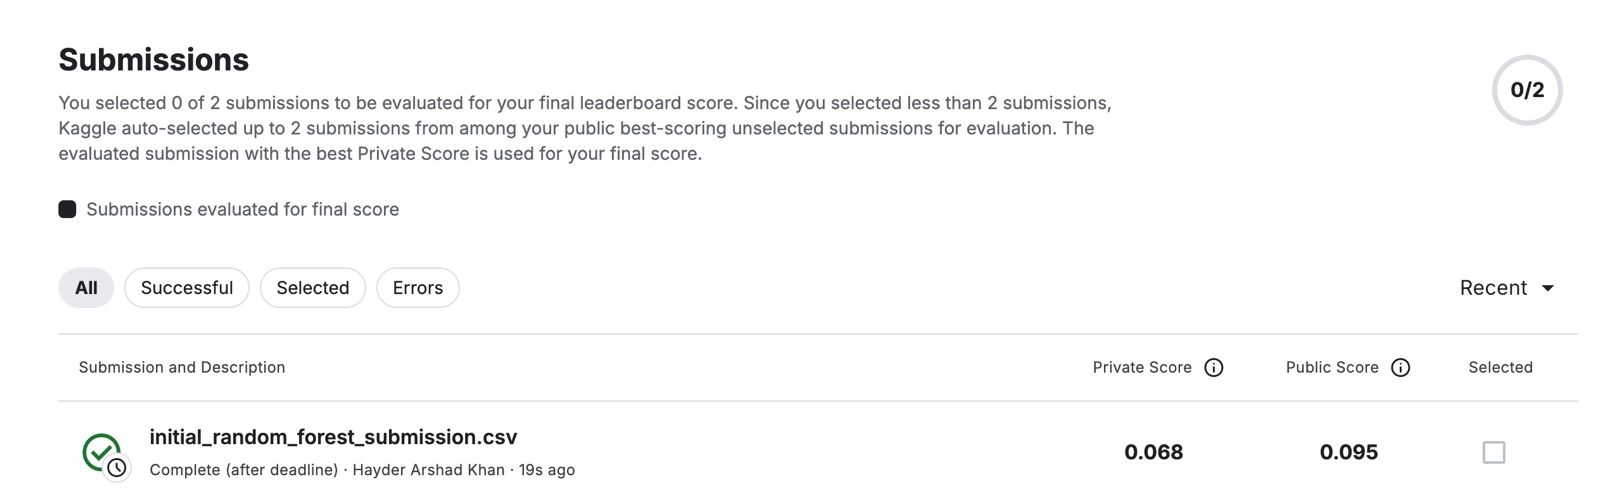

<hr style="width:25%;margin-left:0;"> 

#### 5. Model Improvement and Reflection (2 marks)

Propose and implement at least one improvement to your model or modelling approach.  
- Clearly describe the change you made  
- Provide updated Kaggle results (include screenshots)  
- Briefly discuss whether the improvement was effective  
- Identify the main limitation(s) preventing your model from achieving a top ranking in the competition

In [216]:
# Get feature importance from the best initial Random Forest model

feature_importance = pd.DataFrame({
    "Feature": X_train_encoded.columns,
    "Importance": forest_grid.best_estimator_.feature_importances_
}).sort_values(by="Importance", ascending=False)

feature_importance["Cumulative Importance"] = feature_importance["Importance"].cumsum()

feature_importance.head(30)

,Feature,Importance,Cumulative Importance
23,revenue_per_occupied_day,0.566859,0.566859
4,accommodates,0.072119,0.638978
6,bedrooms,0.058561,0.697540
3,host_listings_count,0.042734,0.740274
15,number_of_reviews_ltm,0.032269,0.772543
7,beds,0.030799,0.803342
5,bathrooms,0.023800,0.827142
13,availability_365,0.019846,0.846988
9,maximum_nights,0.019256,0.866244
0,host_response_rate,0.016827,0.883071


In [217]:
# Select features with meaningful importance

selected_features = feature_importance.loc[
    feature_importance["Importance"] >= 0.005,
    "Feature"
].tolist()

print("Number of selected features:", len(selected_features))
print(selected_features)

Number of selected features: 21
['revenue_per_occupied_day', 'accommodates', 'bedrooms', 'host_listings_count', 'number_of_reviews_ltm', 'beds', 'bathrooms', 'availability_365', 'maximum_nights', 'host_response_rate', 'availability_90', 'availability_60', 'host_acceptance_rate', 'distance_to_city_centre_km', 'availability_30', 'reviews_per_month', 'low_price_amenities_count', 'medium_price_amenities_count', 'minimum_nights', 'property_type_Private room in home', 'room_type_Private room']


In [218]:
# Create reduced feature datasets

X_train_selected = X_train_encoded[selected_features].copy()
X_test_selected = X_test_encoded[selected_features].copy()

print("Selected training shape:", X_train_selected.shape)
print("Selected test shape:", X_test_selected.shape)

Selected training shape: (3735, 21)
Selected test shape: (1601, 21)


In [219]:
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_absolute_percentage_error
import numpy as np
import pandas as pd

# Random Forest with log-transformed target

rf_log_selected_model = TransformedTargetRegressor(
    regressor=RandomForestRegressor(random_state=42, n_jobs=-1),
    func=np.log1p,
    inverse_func=np.expm1
)

# Small targeted grid to keep runtime manageable

rf_log_selected_params = {
    "regressor__n_estimators": [200, 300],
    "regressor__max_depth": [None, 20],
    "regressor__min_samples_leaf": [3, 5],
    "regressor__min_samples_split": [2, 5]
}

rf_log_selected_grid = GridSearchCV(
    estimator=rf_log_selected_model,
    param_grid=rf_log_selected_params,
    cv=5,
    scoring=mape_scorer,
    n_jobs=-1,
    verbose=1
)

rf_log_selected_grid.fit(X_train_selected, y_train)

print("Best improved RF parameters:")
print(rf_log_selected_grid.best_params_)

print("\nBest improved RF CV MAPE:")
print(-rf_log_selected_grid.best_score_)

Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best improved RF parameters:
{'regressor__max_depth': 20, 'regressor__min_samples_leaf': 3, 'regressor__min_samples_split': 2, 'regressor__n_estimators': 300}

Best improved RF CV MAPE:
0.06070943344873494


In [372]:
# Compare the initial and improved Random Forest models

improvement_comparison = pd.DataFrame({
    "Model Version": [
        "Initial Tuned Random Forest",
        "Improved RF: Feature Selection + Log Target"
    ],
    "CV MAPE": [
        -forest_grid.best_score_,
        -rf_log_selected_grid.best_score_
    ],
    "Best Parameters": [
        forest_grid.best_params_,
        rf_log_selected_grid.best_params_
    ]
})

improvement_comparison

,Model Version,CV MAPE,Best Parameters
0,Initial Tuned Random Forest,0.087519,"{'max_depth': None, 'min_samples_leaf': 5, 'n_estimators': 200}"
1,Improved RF: Feature Selection + Log Target,0.060709,"{'regressor__max_depth': 20, 'regressor__min_samples_leaf': 3, 'regressor__min_samples_split': 2, 'regressor__n_estimators': 300}"


In [370]:
# Check overfitting for the improved model

best_improved_model = rf_log_selected_grid.best_estimator_

# Predict prices on the selected training features
improved_train_predictions = best_improved_model.predict(X_train_selected)

# Calculate training MAPE for the improved model
improved_train_mape = mean_absolute_percentage_error(
    y_train,
    improved_train_predictions
)

improved_cv_mape = -rf_log_selected_grid.best_score_

improved_overfit_check = pd.DataFrame({
    "Model": ["Improved RF: Feature Selection + Log Target"],
    "Training MAPE": [improved_train_mape],
    "Cross-Validated MAPE": [improved_cv_mape],
    "Difference": [improved_cv_mape - improved_train_mape]
})

# Display the overfitting check result
improved_overfit_check

,Model,Training MAPE,Cross-Validated MAPE,Difference
0,Improved RF: Feature Selection + Log Target,0.029616,0.060709,0.031094


In [222]:
# Train improved model on full selected training data

best_improved_model = rf_log_selected_grid.best_estimator_

best_improved_model.fit(X_train_selected, y_train)

# Predict test prices

improved_predictions = best_improved_model.predict(X_test_selected)

# Avoid unrealistic negative or very low predictions

improved_predictions = np.clip(improved_predictions, 10, None)

# Create improved Kaggle submission

improved_submission = pd.DataFrame({
    "ID": test_clean["ID"],
    "price": improved_predictions
})

improved_submission.head()

,ID,price
0,3735,231.004147
1,3736,49.011939
2,3737,389.420982
3,3738,175.719605
4,3739,223.957295


In [223]:
# Save improved submission file

improved_submission.to_csv(
    "improved_rf_selected_features_log_target_submission.csv",
    index=False
)

print("Improved Kaggle submission file created.")

Improved Kaggle submission file created.


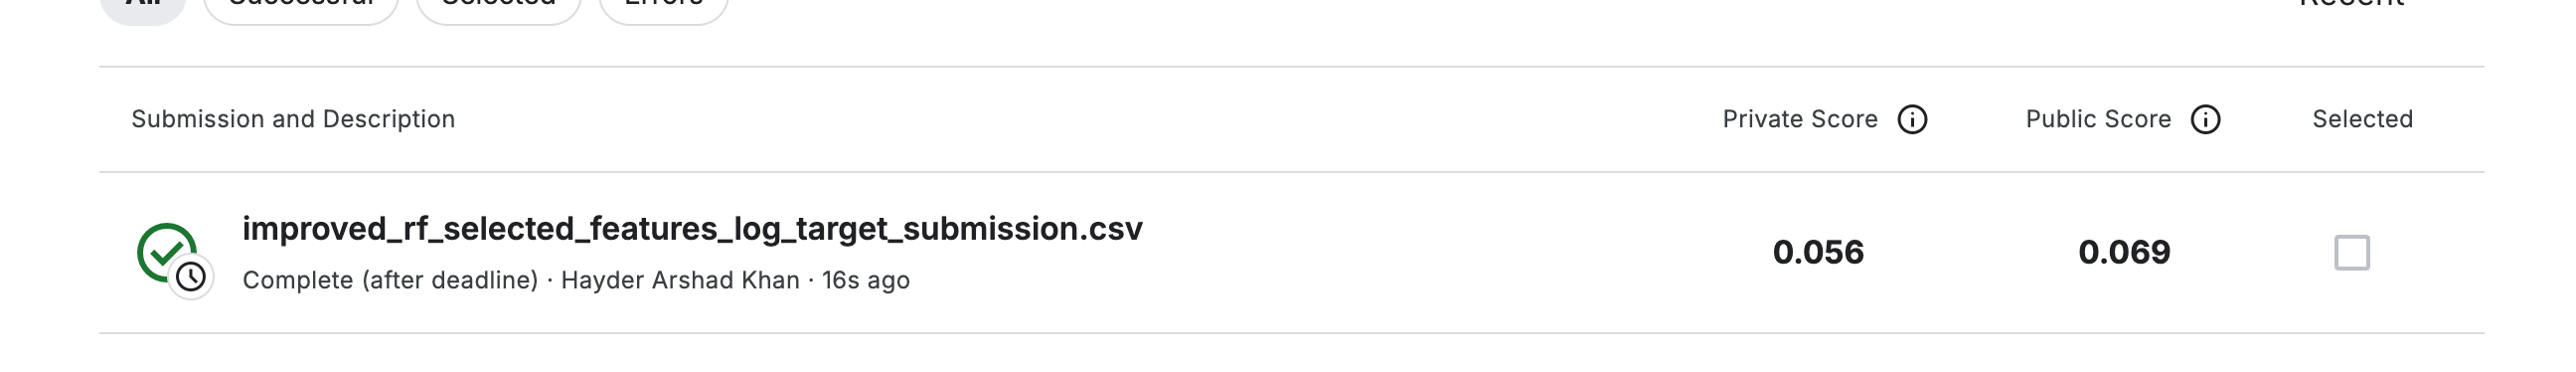

### 5. Model Improvement and Reflection

To improve the best initial model, two changes were implemented: feature selection and log-target transformation.

First, feature selection was applied using Random Forest feature importance. The initial Random Forest model was used to rank predictors based on their importance, and only features with meaningful predictive contribution were retained. This reduced weaker variables that may add noise to the model while keeping the strongest predictors, such as `revenue_per_occupied_day`, property capacity features, availability variables, host response variables, and selected amenity features.

Second, the target variable was transformed using `log(price + 1)` through `TransformedTargetRegressor`. This was used because Airbnb prices are right-skewed and contain expensive outliers. The model was trained on the log-transformed target, but predictions were converted back to normal dollar prices before evaluation and Kaggle submission.

The improved model was also fine-tuned using 5-fold cross-validation. The initial tuned Random Forest achieved a CV MAPE of approximately 0.0875, while the improved feature-selected log-target Random Forest achieved a lower CV MAPE of approximately 0.0607. This shows that the improvement was effective.

The best improved hyperparameters were `max_depth = None`, `min_samples_leaf = 3`, `min_samples_split = 2`, and `n_estimators = 300`. The overfitting check showed a training MAPE of approximately 0.0296 and a cross-validated MAPE of approximately 0.0607. This indicates some overfitting, but the improved model still generalised better than the initial Random Forest.

A key limitation is that the model relies heavily on `revenue_per_occupied_day`, which may be closely related to listing price depending on how estimated revenue was calculated. This may introduce possible target leakage and could partly explain the strong performance. Other limitations include simplified location encoding, limited use of text fields, and using Random Forest rather than more advanced boosting methods such as XGBoost, LightGBM, or CatBoost.

---
---
## Marking Criteria

To receive full marks, your solutions must satisfy the following criteria:

- Correct understanding of the problem and adequate use of additional research  
- Analysis follows best practices discussed in lectures and tutorials  
- Use of intuitive and easily understood visualisations and summary statistic tables 
- Use of appropriate predictive methods in the context of the given problem  
- Python code is clean, concise, and executes without errors  
- Written explanations are clear, complete, and easy to understand  
- Forecasts are correctly generated and uploaded to Kaggle  
- Results are reproducible from the submitted code  
- The assignment notebook is well-organised and easy to follow  
- Video Presentation:
    - Duration less than 15 minutes
    - Each team member delivers a 5-minute presentation on their assigned task  
    - All assignment questions must be discussed in the video  
    - Your code must be clearly readable in the video  
    - Discuss both the actions you took and, more importantly, the reasoning behind these actions, explaining the significance of key steps  
    - Ensure that both your face and Jupyter Notebook are clearly visible during the recording
- Failure to meet the above criteria will result in a deduction of marks  


---
---